In [ ]:
from google.colab import files

uploaded = files.upload()

Saving hazelnut.tar.xz to hazelnut.tar.xz


In [ ]:
import os

dataset_path = "/content/mvtec_hazelnut"

if os.path.exists(dataset_path):
    print("Dataset folder exists!")
    print(os.listdir(dataset_path))
else:
    print("Dataset folder not found. We may need to upload it again.")

Dataset folder exists!
[]


In [ ]:
import os
import tarfile

archive_path = "/content/hazelnut.tar.xz"
extract_path = "/content/mvtec_hazelnut"

os.makedirs(extract_path, exist_ok=True)

with tarfile.open(archive_path, "r:xz") as tar:
    tar.extractall(path=extract_path, filter="data")

print("Dataset extracted successfully!")
print("Folders inside:", os.listdir(extract_path))

FileNotFoundError: [Errno 2] No such file or directory: '/content/hazelnut.tar.xz'

In [ ]:
import os

dataset_path = "/content/mvtec_hazelnut"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

mvtec_hazelnut/


In [ ]:
import os

base_path = "/content/mvtec_hazelnut/hazelnut"

for split in ["train", "test", "ground_truth"]:
    folder = os.path.join(base_path, split)

    print(f"\n{split.upper()}")

    for category in sorted(os.listdir(folder)):
        category_path = os.path.join(folder, category)

        if os.path.isdir(category_path):
            count = len([
                f for f in os.listdir(category_path)
                if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif"))
            ])

            print(f"  {category}: {count} images")


TRAIN


FileNotFoundError: [Errno 2] No such file or directory: '/content/mvtec_hazelnut/hazelnut/train'

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

base_path = "/content/mvtec_hazelnut/hazelnut"

# Find one normal test image and one cracked hazelnut
good_folder = os.path.join(base_path, "test", "good")
crack_folder = os.path.join(base_path, "test", "crack")
mask_folder = os.path.join(base_path, "ground_truth", "crack")

good_file = sorted(os.listdir(good_folder))[0]
crack_file = sorted(os.listdir(crack_folder))[0]

good_image = Image.open(
    os.path.join(good_folder, good_file)
).convert("RGB")

crack_image = Image.open(
    os.path.join(crack_folder, crack_file)
).convert("RGB")

# Find the corresponding defect mask
stem = os.path.splitext(crack_file)[0]
mask_file = stem + "_mask.png"
mask_path = os.path.join(mask_folder, mask_file)

print("Normal image:", good_file)
print("Defective image:", crack_file)
print("Mask found:", os.path.exists(mask_path))

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(good_image)
axes[0].set_title("Normal hazelnut")

axes[1].imshow(crack_image)
axes[1].set_title("Defective hazelnut")

if os.path.exists(mask_path):
    mask = Image.open(mask_path)
    axes[2].imshow(mask, cmap="gray")
    axes[2].set_title("Ground-truth defect mask")
else:
    axes[2].text(0.5, 0.5, "Mask filename not matched",
                 ha="center", va="center")
    axes[2].set_title("Mask check")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/mvtec_hazelnut/hazelnut/test/good'

In [ ]:
import os
from PIL import Image
import numpy as np

base_path = "/content/mvtec_hazelnut/hazelnut"

for split in ["train", "test"]:
    print(f"\n--- {split.upper()} ---")

    split_path = os.path.join(base_path, split)

    for category in sorted(os.listdir(split_path)):
        folder = os.path.join(split_path, category)

        if not os.path.isdir(folder):
            continue

        image_files = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]

        if image_files:
            sample_path = os.path.join(folder, image_files[0])

            with Image.open(sample_path) as image:
                print(
                    f"{category}: {len(image_files)} images | "
                    f"sample size: {image.size} | "
                    f"mode: {image.mode}"
                )

print("\n--- GROUND-TRUTH MASKS ---")

mask_root = os.path.join(base_path, "ground_truth")

for category in sorted(os.listdir(mask_root)):
    folder = os.path.join(mask_root, category)

    if os.path.isdir(folder):
        masks = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]
        print(f"{category}: {len(masks)} masks")


--- TRAIN ---
good: 391 images | sample size: (1024, 1024) | mode: RGB

--- TEST ---
crack: 18 images | sample size: (1024, 1024) | mode: RGB
cut: 17 images | sample size: (1024, 1024) | mode: RGB
good: 40 images | sample size: (1024, 1024) | mode: RGB
hole: 18 images | sample size: (1024, 1024) | mode: RGB
print: 17 images | sample size: (1024, 1024) | mode: RGB

--- GROUND-TRUTH MASKS ---
crack: 18 masks
cut: 17 masks
hole: 18 masks
print: 17 masks


In [ ]:
import os
import numpy as np
from PIL import Image

base_path = "/content/mvtec_hazelnut/hazelnut"
defect_types = ["crack", "cut", "hole", "print"]

for defect in defect_types:
    image_dir = os.path.join(base_path, "test", defect)
    mask_dir = os.path.join(base_path, "ground_truth", defect)

    images = sorted([
        f for f in os.listdir(image_dir)
        if f.lower().endswith(".png")
    ])

    masks = sorted([
        f for f in os.listdir(mask_dir)
        if f.lower().endswith(".png")
    ])

    missing = []
    empty_masks = []
    checked = 0

    for image_file in images:
        stem = os.path.splitext(image_file)[0]
        mask_file = stem + "_mask.png"
        mask_path = os.path.join(mask_dir, mask_file)

        if not os.path.exists(mask_path):
            missing.append(image_file)
            continue

        with Image.open(mask_path) as mask_image:
            mask = np.array(mask_image.convert("L"))

        if not np.any(mask > 0):
            empty_masks.append(mask_file)

        checked += 1

    print(f"\n{defect.upper()}")
    print(f"Images: {len(images)} | Masks: {len(masks)}")
    print(f"Matched pairs: {checked}")
    print(f"Missing masks: {len(missing)}")
    print(f"Empty masks: {len(empty_masks)}")

    if missing:
        print("Examples missing masks:", missing[:3])

print("\nMask validation finished.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/mvtec_hazelnut/hazelnut/test/crack'

In [ ]:
import os
import numpy as np
from PIL import Image

base_path = "/content/mvtec_hazelnut/hazelnut"

print("DEFECT MASK PIXEL SUMMARY")

for defect in ["crack", "cut", "hole", "print"]:
    mask_dir = os.path.join(base_path, "ground_truth", defect)
    total_pixels = 0
    defect_pixels = 0

    for filename in os.listdir(mask_dir):
        if not filename.endswith(".png"):
            continue

        with Image.open(os.path.join(mask_dir, filename)) as img:
            mask = np.array(img.convert("L"))

        total_pixels += mask.size
        defect_pixels += np.count_nonzero(mask > 0)

    percentage = 100 * defect_pixels / total_pixels if total_pixels else 0

    print(
        f"{defect}: {total_pixels:,} pixels | "
        f"{percentage:.3f}% defect pixels"
    )

DEFECT MASK PIXEL SUMMARY
crack: 18,874,368 pixels | 8.401% defect pixels
cut: 17,825,792 pixels | 0.877% defect pixels
hole: 18,874,368 pixels | 1.334% defect pixels
print: 17,825,792 pixels | 2.629% defect pixels


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU for now.")

PyTorch version: 2.11.0+cpu
GPU available: False
Using CPU for now.


In [ ]:
import os
import psutil
import torch

memory = psutil.virtual_memory()

print("CPU cores:", os.cpu_count())
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

CPU cores: 2
Available RAM: 10.72 GB
PyTorch: 2.11.0+cpu
GPU available: False


In [ ]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

base_path = "/content/mvtec_hazelnut/hazelnut"
train_path = os.path.join(base_path, "train", "good")

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

class HazelnutDataset(Dataset):
    def __init__(self, folder, transform=None):
        self.folder = folder
        self.transform = transform
        self.files = sorted([
            os.path.join(folder, f)
            for f in os.listdir(folder)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        image = Image.open(self.files[idx]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image

train_dataset = HazelnutDataset(train_path, transform)
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

batch = next(iter(train_loader))

print("Training images:", len(train_dataset))
print("Batch shape:", batch.shape)
print("Pixel range:", batch.min().item(), "to", batch.max().item())

FileNotFoundError: [Errno 2] No such file or directory: '/content/mvtec_hazelnut/hazelnut/train/good'

In [ ]:
import os

dataset_path = "/content/mvtec_hazelnut/hazelnut"

if os.path.exists(dataset_path):
    print("Dataset found!")

    for folder in ["train", "test", "ground_truth"]:
        path = os.path.join(dataset_path, folder)

        if os.path.exists(path):
            print(f"\n{folder.upper()}")

            for category in os.listdir(path):
                category_path = os.path.join(path, category)

                if os.path.isdir(category_path):
                    count = len(os.listdir(category_path))
                    print(f"{category}: {count} files")
else:
    print("Dataset not found. We need to upload and extract it again.")

Dataset not found. We need to upload and extract it again.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving hazelnut.tar.xz to hazelnut.tar.xz


In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.11.0+cpu
Device: cpu


In [4]:
PROJECT_PATH = "/content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project"

DATASET_PATH = os.path.join(
    PROJECT_PATH, "dataset", "hazelnut"
)

MANIFEST_PATH = os.path.join(
    PROJECT_PATH, "dataset_manifest.csv"
)

print("Project exists:", os.path.exists(PROJECT_PATH))
print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Manifest exists:", os.path.exists(MANIFEST_PATH))

Project exists: True
Dataset exists: True
Manifest exists: True


In [5]:
# Load the existing dataset manifest

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest loaded successfully!")
print("\nColumns:")
print(manifest.columns.tolist())

print("\nDataset split distribution:")
print(manifest.groupby(["split", "category"]).size())

print("\nFirst five records:")
display(manifest.head())

Manifest loaded successfully!

Columns:
['filename', 'image_path', 'category', 'split', 'mask_path', 'label']

Dataset split distribution:
split       category
test        crack         9
            cut           9
            good         59
            hole          9
            print         8
train       good        313
validation  crack         9
            cut           8
            good         59
            hole          9
            print         9
dtype: int64

First five records:


,filename,image_path,category,split,mask_path,label
0,006.png,/content/drive/MyDrive/MSc_Data_Science/ANN_Ha...,good,train,NaN,0
1,307.png,/content/drive/MyDrive/MSc_Data_Science/ANN_Ha...,good,train,NaN,0
2,277.png,/content/drive/MyDrive/MSc_Data_Science/ANN_Ha...,good,train,NaN,0
3,092.png,/content/drive/MyDrive/MSc_Data_Science/ANN_Ha...,good,train,NaN,0
4,227.png,/content/drive/MyDrive/MSc_Data_Science/ANN_Ha...,good,train,NaN,0


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'STAT 11621 Pulse.docx', 'Pulse.xlsx', 'Pulse (1).xlsx', '09.21 Practicals.xlsx', 'DATA SETS', 'Mini tab worksheets', 'SLAB', 'Macro Intro- Les 01', 'CS lab', 'Minitab 01 28.09.docx', 'HNB_DL_RECEIPT_20221125_144240.pdf', 'CS12043 LAB', 'Tutorial 08', 'ps.2020.031-tutorial 4.docx', 'labo4.docx', 'STATLAB 02Y', 'COSC22083', 'Freshers Data.xlsx', 'DILU09.txt', 'Untitled form.gform', 'Untitled form (Responses).gsheet', 'Team Registration (File responses)', 'Team Registration.gform', ' Registration.gform', ' Registration (Responses).gsheet', 'CS 3year', 'Stat lab 3rd y', 'Kasuni', '2024 proposal', 'Jursey Numbers 2024.gsheet', 'CS 3rd year FUll Stack', '8056c17e-dcb2-46f4-9a5a-82b41534c88d.MP4', 'Video.mov', 'Nipulini CV.pdf', 'Untitled spreadsheet.gsheet', 'do this.gsheet', 'UOK team registration Jingle Gam 24.jpg', 'PS_2020_180 (1).pdf', 'PS_2020_180.pdf', 'Pera 3x3 (2).pdf', 'Pera 3x3 (1).pdf', 'Pera 3x3.pdf', 'Orana', 'NBS 113460-LI 0.pdf', 'Tasks Summary.gsheet', '

In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project"

os.makedirs(PROJECT_PATH, exist_ok=True)

print("Project folder created successfully!")

Project folder created successfully!


In [ ]:
import os

print("Files in /content:")

for item in os.listdir("/content"):
    print(item)
print("Dataset successfully saved to Google Drive!")

Files in /content:
.config
drive
sample_data
Dataset successfully saved to Google Drive!


In [ ]:
import os

matches = []

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower() == "hazelnut.tar.xz":
            matches.append(os.path.join(root, file))

print("Dataset archive locations:", matches)

Dataset archive locations: []


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving hazelnut.tar.xz to hazelnut.tar.xz


In [ ]:
import os
import shutil

PROJECT_PATH = "/content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project"

os.makedirs(PROJECT_PATH, exist_ok=True)

SOURCE = "/content/hazelnut.tar.xz"
DESTINATION = os.path.join(PROJECT_PATH, "hazelnut.tar.xz")

shutil.copy2(SOURCE, DESTINATION)

print("Dataset permanently backed up to Google Drive!")

Dataset permanently backed up to Google Drive!


In [ ]:
print("Backup exists:", os.path.exists(DESTINATION))
print("File size (MB):", round(os.path.getsize(DESTINATION) / (1024**2), 2))

Backup exists: True
File size (MB): 588.51


In [ ]:
import tarfile

EXTRACT_PATH = os.path.join(PROJECT_PATH, "dataset")
os.makedirs(EXTRACT_PATH, exist_ok=True)

with tarfile.open(DESTINATION, "r:xz") as tar:
    tar.extractall(path=EXTRACT_PATH, filter="data")

print("Extraction completed!")

Extraction completed!


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project"

DATASET_PATH = os.path.join(PROJECT_PATH, "dataset", "hazelnut")

for folder in ["train", "test", "ground_truth"]:
    folder_path = os.path.join(DATASET_PATH, folder)

    print(f"\n{folder.upper()}")

    for category in sorted(os.listdir(folder_path)):
        category_path = os.path.join(folder_path, category)

        if os.path.isdir(category_path):
            print(f"{category}: {len(os.listdir(category_path))}")


TRAIN
good: 391

TEST
crack: 18
cut: 17
good: 40
hole: 18
print: 17

GROUND_TRUTH
crack: 18
cut: 17
hole: 18
print: 17


In [ ]:
import os
import random
import pandas as pd

# Reproducibility
SEED = 42
random.seed(SEED)

# Dataset paths
DATASET_PATH = "/content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project/dataset/hazelnut"

TRAIN_PATH = os.path.join(DATASET_PATH, "train", "good")
TEST_PATH = os.path.join(DATASET_PATH, "test")
MASK_PATH = os.path.join(DATASET_PATH, "ground_truth")

records = []

# ------------------------------------------------
# 1. NORMAL IMAGES
# ------------------------------------------------

# Original training normal images: 391
train_good = sorted(os.listdir(TRAIN_PATH))

# Original testing normal images: 40
test_good = sorted(os.listdir(os.path.join(TEST_PATH, "good")))

# Combine normal images
normal_images = [
    (os.path.join(TRAIN_PATH, f), f)
    for f in train_good
]

normal_images += [
    (os.path.join(TEST_PATH, "good", f), f)
    for f in test_good
]

# Shuffle with fixed seed
random.shuffle(normal_images)

# Allocate 313 training, 59 validation, 59 testing
normal_train = normal_images[:313]
normal_val = normal_images[313:372]
normal_test = normal_images[372:431]

# Store normal records
for split_name, image_list in [
    ("train", normal_train),
    ("validation", normal_val),
    ("test", normal_test)
]:
    for image_path, filename in image_list:
        records.append({
            "filename": filename,
            "image_path": image_path,
            "category": "good",
            "split": split_name,
            "mask_path": None,
            "label": 0
        })


# ------------------------------------------------
# 2. DEFECTIVE IMAGES
# ------------------------------------------------

# Required distribution
defect_split_counts = {
    "crack": {"validation": 9, "test": 9},
    "cut":   {"validation": 8, "test": 9},
    "hole":  {"validation": 9, "test": 9},
    "print": {"validation": 9, "test": 8}
}

for category, split_counts in defect_split_counts.items():

    category_path = os.path.join(TEST_PATH, category)
    category_mask_path = os.path.join(MASK_PATH, category)

    image_files = sorted(os.listdir(category_path))

    random.shuffle(image_files)

    val_count = split_counts["validation"]

    val_files = image_files[:val_count]
    test_files = image_files[val_count:]

    for split_name, files_list in [
        ("validation", val_files),
        ("test", test_files)
    ]:

        for filename in files_list:

            mask_filename = filename.replace(".png", "_mask.png")

            records.append({
                "filename": filename,
                "image_path": os.path.join(category_path, filename),
                "category": category,
                "split": split_name,
                "mask_path": os.path.join(category_mask_path, mask_filename),
                "label": 1
            })


# ------------------------------------------------
# 3. CREATE DATAFRAME
# ------------------------------------------------

manifest = pd.DataFrame(records)

# Save manifest to Google Drive
MANIFEST_PATH = os.path.join(
    "/content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project",
    "dataset_manifest.csv"
)

manifest.to_csv(MANIFEST_PATH, index=False)

print("Dataset split created successfully!")
print("Manifest saved to:", MANIFEST_PATH)


Dataset split created successfully!
Manifest saved to: /content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project/dataset_manifest.csv


In [ ]:
summary = pd.crosstab(
    manifest["split"],
    manifest["category"],
    margins=True
)

print(summary)

category    crack  cut  good  hole  print  All
split                                         
test            9    9    59     9      8   94
train           0    0   313     0      0  313
validation      9    8    59     9      9   94
All            18   17   431    18     17  501


In [ ]:
missing_images = manifest[
    ~manifest["image_path"].apply(os.path.exists)
]

defect_records = manifest[manifest["label"] == 1]

missing_masks = defect_records[
    ~defect_records["mask_path"].apply(os.path.exists)
]

print("Missing images:", len(missing_images))
print("Missing masks:", len(missing_masks))

print("Total records:", len(manifest))
print("Training images:", len(manifest[manifest["split"] == "train"]))
print("Validation images:", len(manifest[manifest["split"] == "validation"]))
print("Testing images:", len(manifest[manifest["split"] == "test"]))

Missing images: 0
Missing masks: 0
Total records: 501
Training images: 313
Validation images: 94
Testing images: 94


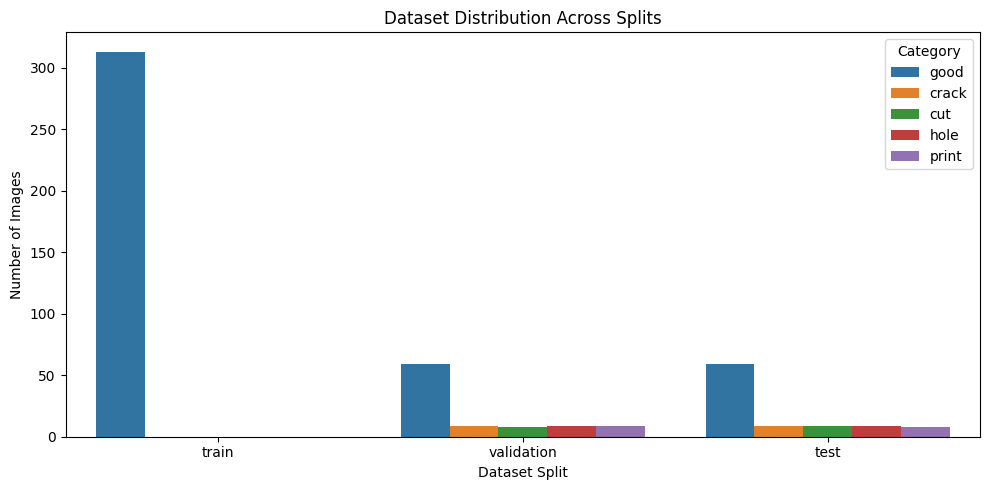

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

plt.figure(figsize=(10, 5))

sns.countplot(
    data=manifest,
    x="split",
    hue="category"
)

plt.title("Dataset Distribution Across Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.legend(title="Category")
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project/eda_01_dataset_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

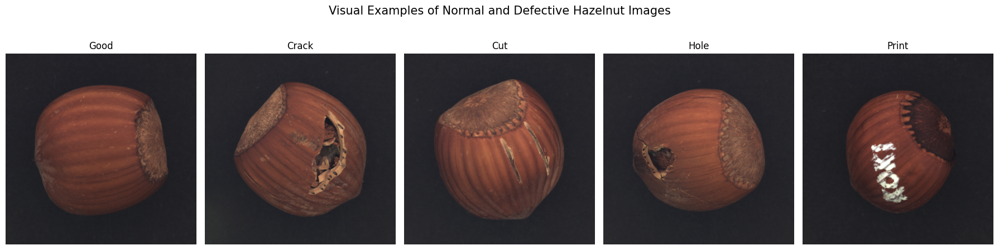

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

categories = ["good", "crack", "cut", "hole", "print"]

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, category in zip(axes, categories):

    # Select an image from the dataset
    samples = manifest[
        (manifest["category"] == category) &
        (manifest["split"] == "validation")
    ]

    sample = samples.sample(n=1, random_state=42).iloc[0]

    # Load image
    image = Image.open(sample["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(category.capitalize())
    ax.axis("off")

plt.suptitle("Visual Examples of Normal and Defective Hazelnut Images",
             fontsize=15)

plt.tight_layout()
plt.show()

In [ ]:
fig.savefig(
    "/content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project/eda_02_visual_inspection.png",
    dpi=300,
    bbox_inches="tight"
)

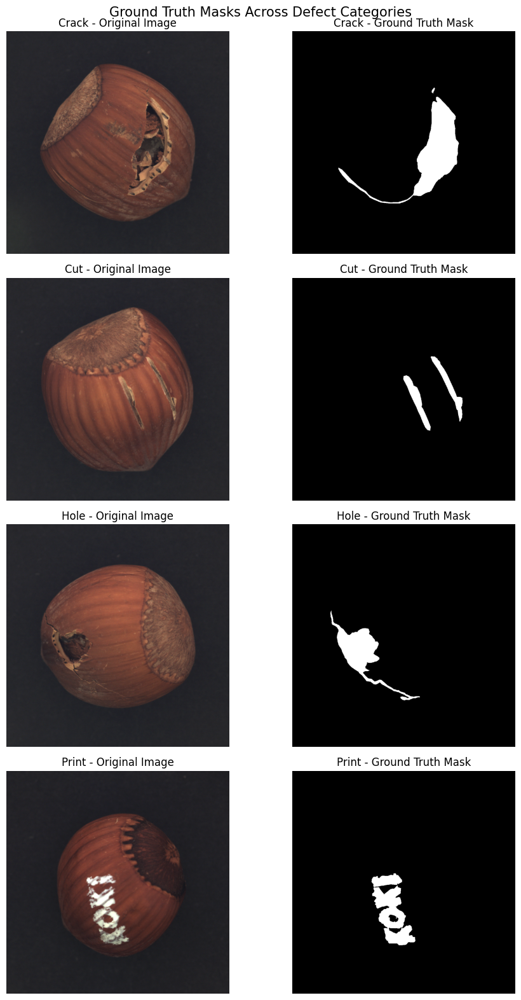

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

categories = ["crack", "cut", "hole", "print"]

fig, axes = plt.subplots(4, 2, figsize=(10, 16))

for row, category in enumerate(categories):

    sample = manifest[
        (manifest["category"] == category) &
        (manifest["split"] == "validation")
    ].sample(n=1, random_state=42).iloc[0]

    image = Image.open(sample["image_path"]).convert("RGB")
    mask = Image.open(sample["mask_path"]).convert("L")

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{category.capitalize()} - Original Image")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title(f"{category.capitalize()} - Ground Truth Mask")
    axes[row, 1].axis("off")

plt.suptitle("Ground Truth Masks Across Defect Categories", fontsize=15)
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project/eda_05_ground_truth_masks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import os
import pandas as pd
from PIL import Image

image_properties = []

for _, row in manifest.iterrows():

    image = Image.open(row["image_path"])

    image_properties.append({
        "filename": row["filename"],
        "category": row["category"],
        "split": row["split"],
        "width": image.width,
        "height": image.height,
        "mode": image.mode,
        "format": image.format
    })

properties_df = pd.DataFrame(image_properties)

print("IMAGE DIMENSION SUMMARY")
print(properties_df[["width", "height"]].describe())

print("\nIMAGE MODES")
print(properties_df["mode"].value_counts())

print("\nIMAGE FORMATS")
print(properties_df["format"].value_counts())

print("\nDIMENSIONS BY CATEGORY")
print(properties_df.groupby("category")[["width", "height"]].agg(["min", "max", "mean"]))

IMAGE DIMENSION SUMMARY
        width  height
count   501.0   501.0
mean   1024.0  1024.0
std       0.0     0.0
min    1024.0  1024.0
25%    1024.0  1024.0
50%    1024.0  1024.0
75%    1024.0  1024.0
max    1024.0  1024.0

IMAGE MODES
mode
RGB    501
Name: count, dtype: int64

IMAGE FORMATS
format
PNG    501
Name: count, dtype: int64

DIMENSIONS BY CATEGORY
         width               height              
           min   max    mean    min   max    mean
category                                         
crack     1024  1024  1024.0   1024  1024  1024.0
cut       1024  1024  1024.0   1024  1024  1024.0
good      1024  1024  1024.0   1024  1024  1024.0
hole      1024  1024  1024.0   1024  1024  1024.0
print     1024  1024  1024.0   1024  1024  1024.0


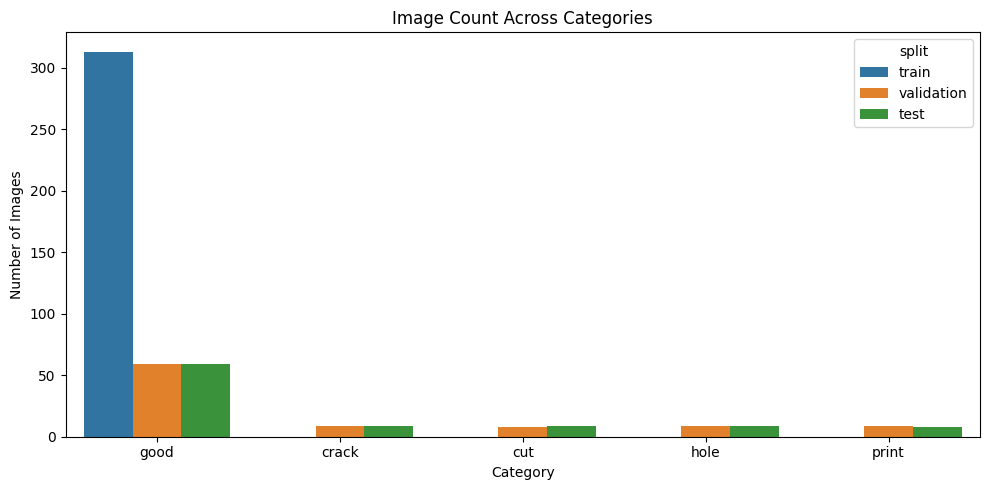

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=properties_df,
    x="category",
    hue="split"
)

plt.title("Image Count Across Categories")
plt.xlabel("Category")
plt.ylabel("Number of Images")

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "eda_04_image_properties.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

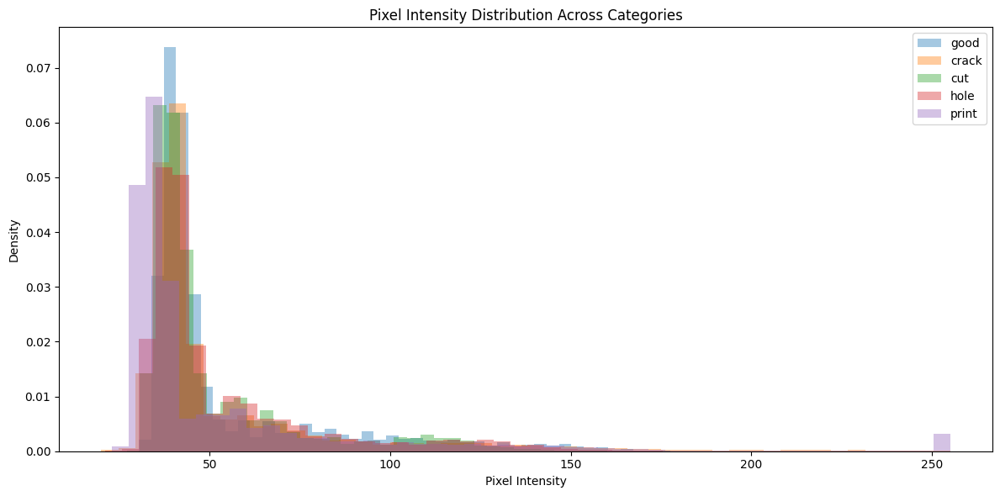

In [ ]:
import numpy as np
from PIL import Image

categories = ["good", "crack", "cut", "hole", "print"]

plt.figure(figsize=(12, 6))

for category in categories:

    sample = manifest[
        manifest["category"] == category
    ].iloc[0]

    image = Image.open(sample["image_path"]).convert("RGB")

    pixels = np.array(image)

    plt.hist(
        pixels.ravel(),
        bins=50,
        density=True,
        alpha=0.4,
        label=category
    )

plt.title("Pixel Intensity Distribution Across Categories")
plt.xlabel("Pixel Intensity")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "eda_04_pixel_intensity.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print("PyTorch version:", torch.__version__)
print("Imports completed successfully!")

PyTorch version: 2.11.0+cpu
Imports completed successfully!


In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image

defect_records = []

defect_manifest = manifest[
    (manifest["label"] == 1) &
    (manifest["split"].isin(["validation", "test"]))
]

for _, row in defect_manifest.iterrows():

    mask = np.array(Image.open(row["mask_path"]).convert("L"))

    total_pixels = mask.size
    defect_pixels = np.sum(mask > 0)

    defect_percentage = (defect_pixels / total_pixels) * 100

    defect_records.append({
        "filename": row["filename"],
        "category": row["category"],
        "split": row["split"],
        "defect_pixels": defect_pixels,
        "total_pixels": total_pixels,
        "defect_percentage": defect_percentage
    })

defect_pixel_df = pd.DataFrame(defect_records)

display(defect_pixel_df.head())

,filename,category,split,defect_pixels,total_pixels,defect_percentage
0,010.png,crack,validation,290021,1048576,27.658558
1,006.png,crack,validation,42808,1048576,4.082489
2,011.png,crack,validation,80208,1048576,7.649231
3,007.png,crack,validation,234892,1048576,22.401047
4,008.png,crack,validation,146408,1048576,13.962555


In [ ]:
defect_summary = (
    defect_pixel_df
    .groupby("category")["defect_percentage"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

display(defect_summary)

,count,mean,median,min,max
category,,,,,
crack,18,8.401,4.700,1.281,27.659
cut,17,0.877,0.786,0.397,2.017
hole,18,1.334,1.236,0.233,2.935
print,17,2.629,2.436,1.517,4.827


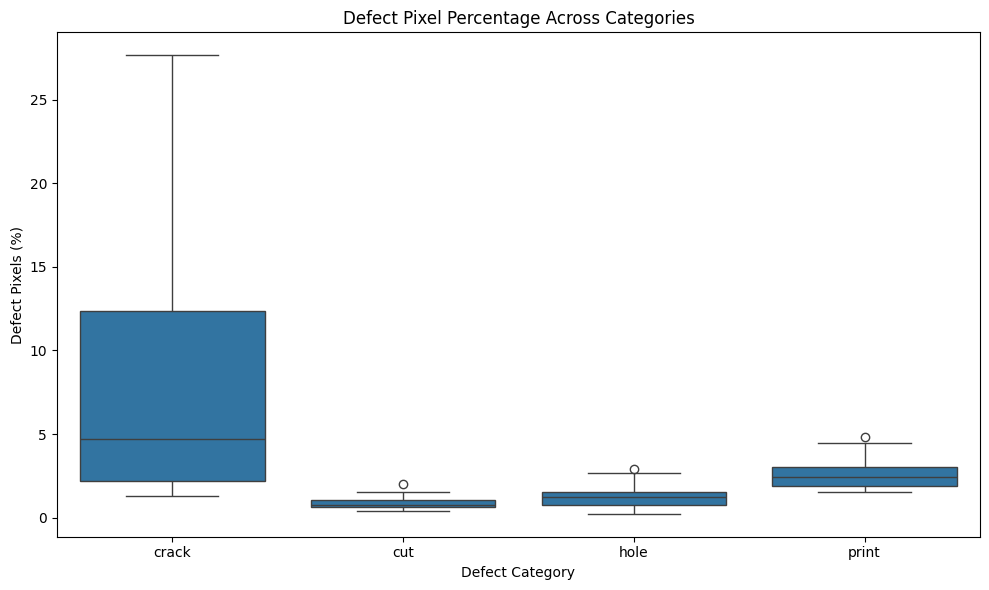

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=defect_pixel_df,
    x="category",
    y="defect_percentage"
)

plt.title("Defect Pixel Percentage Across Categories")
plt.xlabel("Defect Category")
plt.ylabel("Defect Pixels (%)")
plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "eda_06_defect_pixel_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

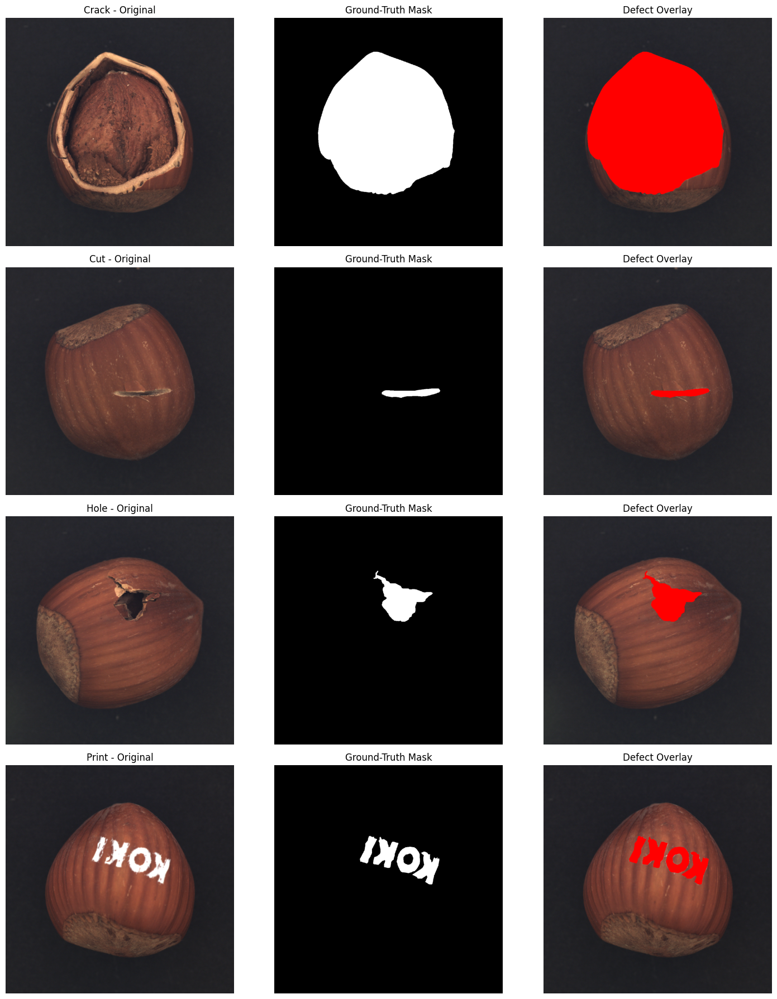

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import os

defect_categories = ["crack", "cut", "hole", "print"]

fig, axes = plt.subplots(4, 3, figsize=(15, 18))

for i, category in enumerate(defect_categories):

    sample = manifest[
        (manifest["category"] == category) &
        (manifest["label"] == 1) &
        (manifest["split"] == "validation")
    ].iloc[0]

    image = np.array(Image.open(sample["image_path"]).convert("RGB"))
    mask = np.array(Image.open(sample["mask_path"]).convert("L"))

    # Create overlay
    overlay = image.copy()
    overlay[mask > 0] = [255, 0, 0]

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"{category.title()} - Original")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Ground-Truth Mask")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("Defect Overlay")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "eda_07_ground_truth_overlays.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print("Manifest shape:", manifest.shape)

print("\nImages by split:")
print(manifest["split"].value_counts())

print("\nImages by category:")
print(manifest.groupby(["split", "category"]).size())

print("\nMissing image paths:", manifest["image_path"].isna().sum())
print("Missing mask paths:",
      manifest[manifest["label"] == 1]["mask_path"].isna().sum())

Manifest shape: (501, 6)

Images by split:
split
train         313
validation     94
test           94
Name: count, dtype: int64

Images by category:
split       category
test        crack         9
            cut           9
            good         59
            hole          9
            print         8
train       good        313
validation  crack         9
            cut           8
            good         59
            hole          9
            print         9
dtype: int64

Missing image paths: 0
Missing mask paths: 0


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.11.0+cpu
Device: cpu


In [8]:
IMAGE_SIZE = 128

class HazelnutDataset(Dataset):

    def __init__(self, dataframe, image_size=128):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load and preprocess image
        image = Image.open(row["image_path"]).convert("RGB")

        image = image.resize(
            (self.image_size, self.image_size),
            Image.Resampling.BILINEAR
        )

        image_array = np.asarray(image, dtype=np.float32) / 255.0

        image_tensor = torch.from_numpy(
            image_array.transpose(2, 0, 1)
        )

        # Load ground-truth mask
        if row["label"] == 1:

            mask = Image.open(row["mask_path"]).convert("L")

            mask = mask.resize(
                (self.image_size, self.image_size),
                Image.Resampling.NEAREST
            )

            mask_array = (np.asarray(mask) > 0).astype(np.float32)

        else:
            mask_array = np.zeros(
                (self.image_size, self.image_size),
                dtype=np.float32
            )

        mask_tensor = torch.from_numpy(mask_array).unsqueeze(0)

        return {
            "image": image_tensor,
            "mask": mask_tensor,
            "label": torch.tensor(row["label"], dtype=torch.long),
            "category": row["category"],
            "filename": row["filename"]
        }

In [9]:
train_df = manifest[manifest["split"] == "train"].copy()

val_df = manifest[manifest["split"] == "validation"].copy()

test_df = manifest[manifest["split"] == "test"].copy()

train_dataset = HazelnutDataset(train_df)
val_dataset = HazelnutDataset(val_df)
test_dataset = HazelnutDataset(test_df)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 313
Validation images: 94
Testing images: 94


In [10]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [ ]:
sample = train_dataset[0]

print("Image shape:", sample["image"].shape)
print("Mask shape:", sample["mask"].shape)

print("Image minimum:", sample["image"].min().item())
print("Image maximum:", sample["image"].max().item())

print("Mask unique values:", torch.unique(sample["mask"]))

Image shape: torch.Size([3, 128, 128])
Mask shape: torch.Size([1, 128, 128])
Image minimum: 0.125490203499794
Image maximum: 0.6980392336845398
Mask unique values: tensor([0.])


In [ ]:
# Find one defective image from the validation dataset
defect_sample = next(
    val_dataset[i]
    for i in range(len(val_dataset))
    if val_dataset[i]["label"].item() == 1
)

print("Category:", defect_sample["category"])
print("Image shape:", defect_sample["image"].shape)
print("Mask shape:", defect_sample["mask"].shape)
print("Mask unique values:", torch.unique(defect_sample["mask"]))
print("Defect pixels:", defect_sample["mask"].sum().item())

Category: crack
Image shape: torch.Size([3, 128, 128])
Mask shape: torch.Size([1, 128, 128])
Mask unique values: tensor([0., 1.])
Defect pixels: 4538.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pandas as pd
import numpy as np
import torch

PROJECT_PATH = "/content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project"

DATASET_PATH = os.path.join(
    PROJECT_PATH, "dataset", "hazelnut"
)

print("Project exists:", os.path.exists(PROJECT_PATH))
print("Dataset exists:", os.path.exists(DATASET_PATH))

Project exists: True
Dataset exists: True


In [ ]:
import pandas as pd

manifest = pd.read_csv(
    os.path.join(PROJECT_PATH, "dataset_manifest.csv")
)

print("Manifest shape:", manifest.shape)
print(manifest["split"].value_counts())

Manifest shape: (501, 6)
split
train         313
validation     94
test           94
Name: count, dtype: int64


In [ ]:
print("PyTorch version:", torch.__version__)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

PyTorch version: 2.11.0+cpu
Training images: 313
Validation images: 94
Test images: 94


NameError: name 'train_loader' is not defined

In [12]:
import torch
import torch.nn as nn

class CNN_Autoencoder(nn.Module):

    def __init__(self):
        super(CNN_Autoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(16, 3, kernel_size=2, stride=2),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)

        return decoded

In [13]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_exp1 = CNN_Autoencoder().to(device)

model_path = os.path.join(
    PROJECT_PATH,
    "cnn_autoencoder_experiment_1.pth"
)

model_exp1.load_state_dict(
    torch.load(
        model_path,
        map_location=device,
        weights_only=True
    )
)

model_exp1.eval()

print("Experiment 1 model loaded successfully!")
print("Device:", device)

Experiment 1 model loaded successfully!
Device: cpu


In [14]:
print("Model:", model_exp1 is not None)
print("Validation loader:", val_loader is not None)
print("Device:", device)

print("Validation images:", len(val_loader.dataset))

Model: True
Validation loader: True
Device: cpu
Validation images: 94


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CNN_Autoencoder().to(device)

print("Device:", device)
print(model)

Device: cpu
CNN_Autoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(2, 2), stride=(2, 2))
    (1): ReLU()
    (2): ConvTranspose2d(64, 32, kernel_size=(2, 2), stride=(2, 2))
    (3): ReLU()
    (4): ConvTranspose2d(32, 16, kernel_size=(

In [ ]:
batch = next(iter(train_loader))

sample_images = batch["image"].to(device)
sample_masks = batch["mask"].to(device)

with torch.no_grad():
    reconstructed = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", reconstructed.shape)
print("Mask shape:", sample_masks.shape)

Input shape: torch.Size([8, 3, 128, 128])
Output shape: torch.Size([8, 3, 128, 128])
Mask shape: torch.Size([8, 1, 128, 128])


In [ ]:
# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training configuration
num_epochs = 30

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Maximum epochs:", num_epochs)
print("Device:", device)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Maximum epochs: 30
Device: cpu


In [11]:
from torch.utils.data import DataLoader, Subset

# Select only normal images from validation
normal_val_indices = [
    i for i in range(len(val_dataset))
    if val_dataset[i]["label"] == 0
]

normal_val_dataset = Subset(val_dataset, normal_val_indices)

normal_val_loader = DataLoader(
    normal_val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Normal validation images:", len(normal_val_dataset))

Normal validation images: 59


In [ ]:
from copy import deepcopy

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_model_weights = None

patience = 5
epochs_without_improvement = 0

for epoch in range(num_epochs):

    # Training
    model.train()
    running_train_loss = 0.0

    for batch in train_loader:

        images = batch["image"].to(device)

        optimizer.zero_grad()

        reconstructed = model(images)

        loss = criterion(reconstructed, images)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)

    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for batch in normal_val_loader:

            images = batch["image"].to(device)

            reconstructed = model(images)

            loss = criterion(reconstructed, images)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(normal_val_loader)

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Training Loss: {epoch_train_loss:.6f} "
        f"Validation Loss: {epoch_val_loss:.6f}"
    )

    # Early stopping
    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss
        best_model_weights = deepcopy(model.state_dict())

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:

        print("Early stopping triggered.")
        break

# Restore best model
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)

print("\nTraining completed!")
print("Best validation loss:", best_val_loss)

Epoch [1/30] Training Loss: 0.074667 Validation Loss: 0.017120
Epoch [2/30] Training Loss: 0.008961 Validation Loss: 0.006855
Epoch [3/30] Training Loss: 0.006545 Validation Loss: 0.006398
Epoch [4/30] Training Loss: 0.006318 Validation Loss: 0.006152
Epoch [5/30] Training Loss: 0.006037 Validation Loss: 0.005934
Epoch [6/30] Training Loss: 0.005747 Validation Loss: 0.005776
Epoch [7/30] Training Loss: 0.005536 Validation Loss: 0.005416
Epoch [8/30] Training Loss: 0.005206 Validation Loss: 0.005136
Epoch [9/30] Training Loss: 0.004865 Validation Loss: 0.004755
Epoch [10/30] Training Loss: 0.004432 Validation Loss: 0.004174
Epoch [11/30] Training Loss: 0.003631 Validation Loss: 0.003043
Epoch [12/30] Training Loss: 0.002192 Validation Loss: 0.001574
Epoch [13/30] Training Loss: 0.001308 Validation Loss: 0.001291
Epoch [14/30] Training Loss: 0.001086 Validation Loss: 0.001046
Epoch [15/30] Training Loss: 0.001019 Validation Loss: 0.001059
Epoch [16/30] Training Loss: 0.000916 Validation 

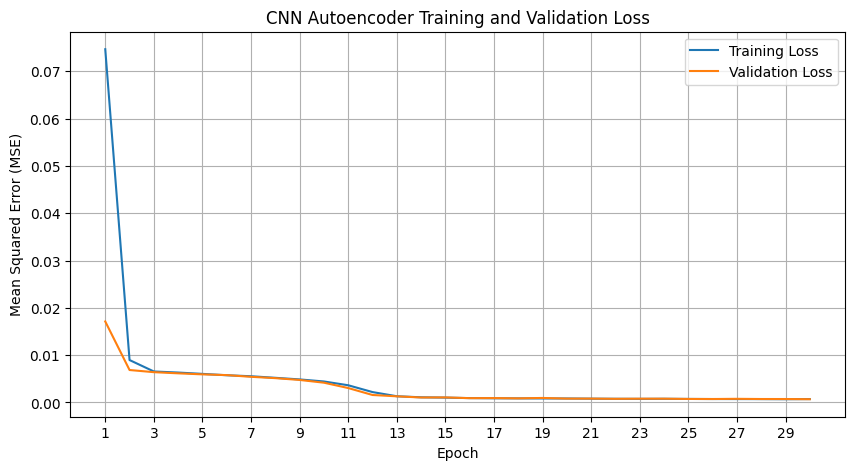

In [ ]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.title("CNN Autoencoder Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")

plt.xticks(range(1, len(train_losses) + 1, 2))
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(PROJECT_PATH, "training_learning_curves.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
import torch

model.eval()

results = []

with torch.no_grad():

    for batch in val_loader:

        images = batch["image"].to(device)

        # Reconstruct images
        reconstructed = model(images)

        # Calculate pixel-wise reconstruction error
        pixel_errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=1
        )

        # Calculate one anomaly score per image
        anomaly_scores = pixel_errors.mean(dim=(1, 2))

        for i in range(len(images)):

            results.append({
                "filename": batch["filename"][i],
                "category": batch["category"][i],
                "label": int(batch["label"][i]),
                "anomaly_score": anomaly_scores[i].item()
            })

# Create results DataFrame
val_results = pd.DataFrame(results)

# Save results
val_results.to_csv(
    os.path.join(PROJECT_PATH, "validation_anomaly_scores.csv"),
    index=False
)

print("Total validation images:", len(val_results))
print("\nAnomaly scores:")
print(val_results.head(10))

Total validation images: 94

Anomaly scores:
  filename category  label  anomaly_score
0  378.png     good      0       0.000442
1  073.png     good      0       0.000716
2  234.png     good      0       0.000583
3  202.png     good      0       0.000503
4  255.png     good      0       0.000692
5  368.png     good      0       0.000643
6  340.png     good      0       0.000806
7  290.png     good      0       0.001159
8  108.png     good      0       0.000628
9  033.png     good      0       0.000452


In [ ]:
print(
    val_results.groupby("category")["anomaly_score"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

          count      mean    median       min       max
category                                               
crack         9  0.002900  0.002646  0.000582  0.006170
print         9  0.002692  0.002167  0.001237  0.005264
hole          9  0.000885  0.000838  0.000613  0.001473
cut           8  0.000711  0.000693  0.000383  0.001016
good         59  0.000674  0.000636  0.000346  0.001419


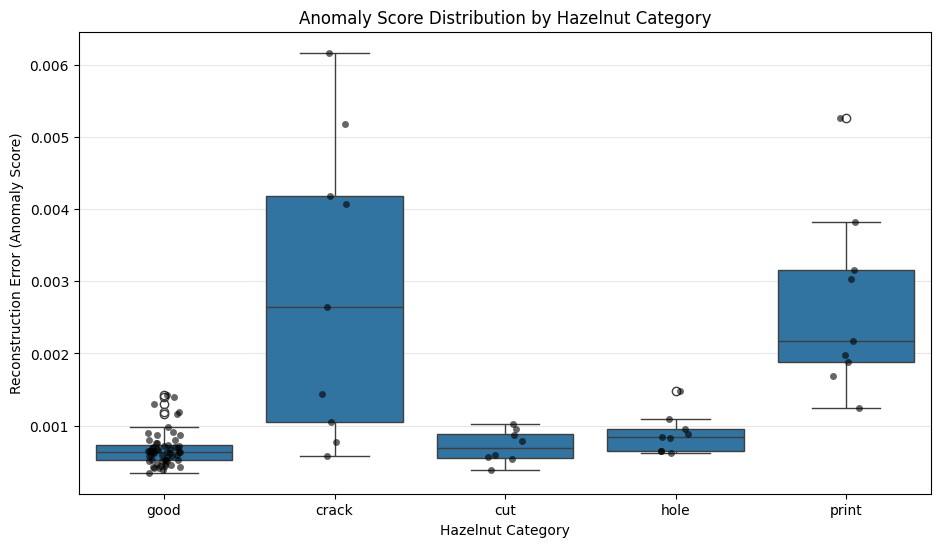

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=val_results,
    x="category",
    y="anomaly_score"
)

sns.stripplot(
    data=val_results,
    x="category",
    y="anomaly_score",
    color="black",
    alpha=0.6,
    jitter=True
)

plt.title("Anomaly Score Distribution by Hazelnut Category")
plt.xlabel("Hazelnut Category")
plt.ylabel("Reconstruction Error (Anomaly Score)")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    os.path.join(PROJECT_PATH, "anomaly_score_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    classification_report,
    confusion_matrix
)

import numpy as np

# Actual labels and anomaly scores
y_true = val_results["label"].values
y_scores = val_results["anomaly_score"].values

# Calculate evaluation metrics
roc_auc = roc_auc_score(y_true, y_scores)

average_precision = average_precision_score(
    y_true,
    y_scores
)

print("VALIDATION PERFORMANCE")
print("----------------------")
print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision:", round(average_precision, 4))

VALIDATION PERFORMANCE
----------------------
ROC-AUC: 0.8073
Average Precision: 0.7893


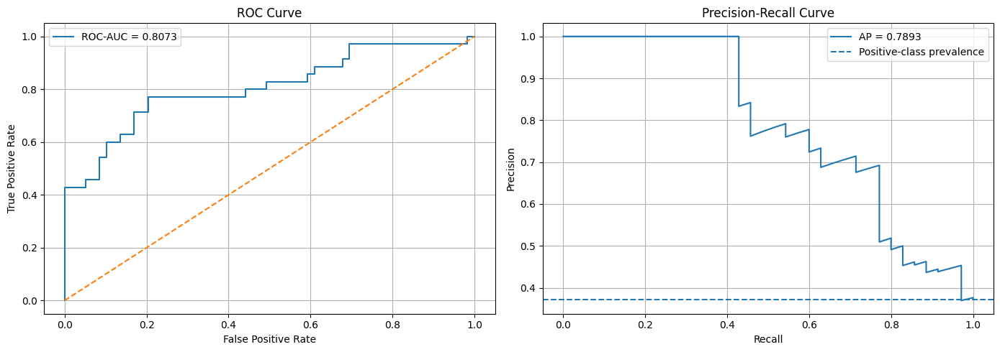

In [ ]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc
)

import matplotlib.pyplot as plt

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores)

# Precision-Recall curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_true, y_scores
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC plot
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
axes[0].plot([0, 1], [0, 1], linestyle="--")

axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(True)

# Precision-Recall plot
axes[1].plot(recall, precision, label=f"AP = {average_precision:.4f}")

axes[1].axhline(
    y=np.mean(y_true),
    linestyle="--",
    label="Positive-class prevalence"
)

axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "roc_pr_curves.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    f1_score
)

# Calculate precision, recall and thresholds
precision, recall, thresholds = precision_recall_curve(
    y_true,
    y_scores
)

# Calculate F1 for each available threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

# Find threshold with highest F1
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

# Make predictions
y_pred = (y_scores >= best_threshold).astype(int)

print("BEST VALIDATION THRESHOLD")
print("-------------------------")
print("Threshold:", best_threshold)
print("Precision:", precision[best_index])
print("Recall:", recall[best_index])
print("F1-score:", f1_scores[best_index])

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("\nCONFUSION MATRIX")
print(cm)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Defective"],
    zero_division=0
))

BEST VALIDATION THRESHOLD
-------------------------
Threshold: 0.0007773775141686201
Precision: 0.6923076923076923
Recall: 0.7714285714285715
F1-score: 0.7297297296798757

CONFUSION MATRIX
[[47 12]
 [ 8 27]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.85      0.80      0.82        59
   Defective       0.69      0.77      0.73        35

    accuracy                           0.79        94
   macro avg       0.77      0.78      0.78        94
weighted avg       0.79      0.79      0.79        94



In [ ]:
# Add predictions to validation results
val_results["predicted_label"] = y_pred

# Identify incorrect predictions
errors = val_results[
    val_results["label"] != val_results["predicted_label"]
].copy()

print("Total incorrect predictions:", len(errors))

print("\nIncorrect predictions by category:")

print(
    errors.groupby(["category", "label"])
    .size()
    .reset_index(name="error_count")
)

print("\nFALSE POSITIVES:")
print(
    errors[errors["label"] == 0][
        ["filename", "category", "anomaly_score"]
    ]
)

print("\nFALSE NEGATIVES:")
print(
    errors[errors["label"] == 1][
        ["filename", "category", "anomaly_score"]
    ]
)


Total incorrect predictions: 20

Incorrect predictions by category:
  category  label  error_count
0    crack      1            1
1      cut      1            4
2     good      0           12
3     hole      1            3

FALSE POSITIVES:
   filename category  anomaly_score
6   340.png     good       0.000806
7   290.png     good       0.001159
19  039.png     good       0.000866
25  273.png     good       0.001389
28  311.png     good       0.001419
30  331.png     good       0.000979
34  181.png     good       0.000868
35  189.png     good       0.000795
42  051.png     good       0.000893
51  098.png     good       0.000913
52  295.png     good       0.001182
57  282.png     good       0.001296

FALSE NEGATIVES:
   filename category  anomaly_score
64  014.png    crack       0.000582
68  007.png      cut       0.000383
71  009.png      cut       0.000597
72  014.png      cut       0.000559
74  010.png      cut       0.000536
77  008.png     hole       0.000640
78  001.png     hole 

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get validation dataset samples
false_positives = errors[errors["label"] == 0]
false_negatives = errors[errors["label"] == 1]

def show_errors(error_df, title):

    n = len(error_df)

    fig, axes = plt.subplots(
        n, 2,
        figsize=(9, n * 2.5),
        squeeze=False
    )

    for row, (_, result) in enumerate(error_df.iterrows()):

        sample = next(
            val_dataset[i]
            for i in range(len(val_dataset))
            if val_dataset[i]["filename"] == result["filename"]
            and val_dataset[i]["category"] == result["category"]
        )

        image = sample["image"].permute(1, 2, 0).numpy()
        mask = sample["mask"].squeeze().numpy()

        axes[row, 0].imshow(image)
        axes[row, 0].set_title(
            f'{result["filename"]} - Original'
        )

        axes[row, 1].imshow(image)

        # Display only actual defect pixels
        masked_defects = np.ma.masked_where(
            mask == 0,
            mask
        )

        axes[row, 1].imshow(
            masked_defects,
            cmap="Reds",
            alpha=0.6,
            vmin=0,
            vmax=1
        )

        axes[row, 1].set_title("Ground Truth Defect Overlay")

        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

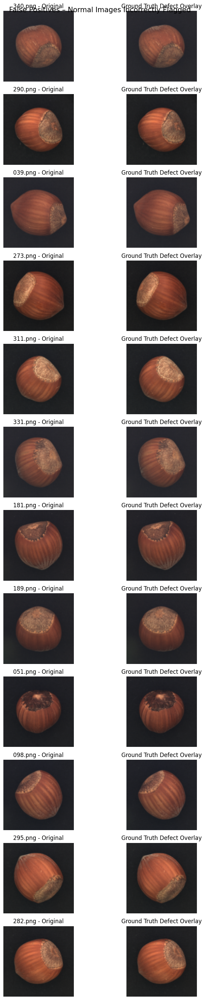

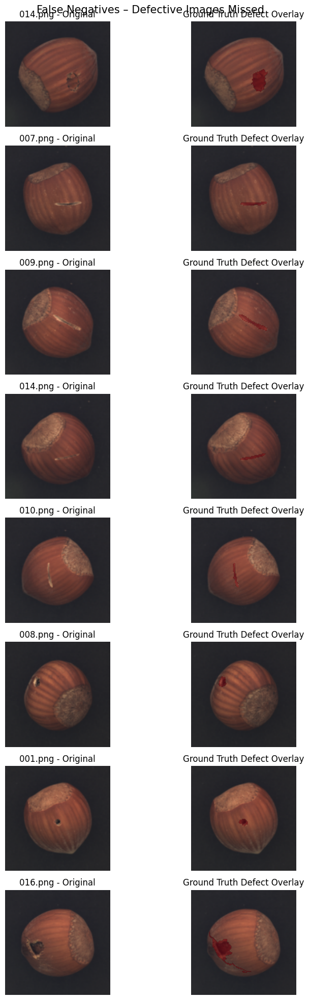

In [ ]:
show_errors(
    false_positives,
    "False Positives – Normal Images Incorrectly Flagged"
)

show_errors(
    false_negatives,
    "False Negatives – Defective Images Missed"
)

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()

def show_anomaly_heatmaps(error_df):

    for _, result in error_df.iterrows():

        # Find the corresponding image
        sample = next(
            val_dataset[i]
            for i in range(len(val_dataset))
            if val_dataset[i]["filename"] == result["filename"]
            and val_dataset[i]["category"] == result["category"]
        )

        image = sample["image"].unsqueeze(0).to(device)
        ground_truth = sample["mask"].squeeze().numpy()

        # Reconstruct image
        with torch.no_grad():
            reconstructed = model(image)

        # Convert tensors to numpy
        original = image.squeeze(0).cpu().permute(1, 2, 0).numpy()

        reconstructed_image = (
            reconstructed.squeeze(0)
            .cpu()
            .permute(1, 2, 0)
            .numpy()
        )

        # Calculate pixel-wise anomaly map
        anomaly_map = torch.mean(
            (image - reconstructed) ** 2,
            dim=1
        ).squeeze().cpu().numpy()

        # Display four visualisations
        fig, axes = plt.subplots(1, 4, figsize=(16, 4))

        axes[0].imshow(original)
        axes[0].set_title("Original Image")

        axes[1].imshow(reconstructed_image)
        axes[1].set_title("Reconstructed Image")

        heatmap = axes[2].imshow(anomaly_map, cmap="hot")
        axes[2].set_title("Anomaly Heatmap")
        plt.colorbar(heatmap, ax=axes[2], fraction=0.046)

        axes[3].imshow(original)
        axes[3].imshow(
            np.ma.masked_where(ground_truth == 0, ground_truth),
            cmap="Reds",
            alpha=0.7,
            vmin=0,
            vmax=1
        )
        axes[3].set_title("Ground-truth Defect")

        for ax in axes:
            ax.axis("off")

        fig.suptitle(
            f'{result["filename"]} | {result["category"]} | '
            f'Anomaly score: {result["anomaly_score"]:.6f}',
            fontsize=12
        )

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                PROJECT_PATH,
                f'heatmap_FN_{result["category"]}_{result["filename"]}'
            ),
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()

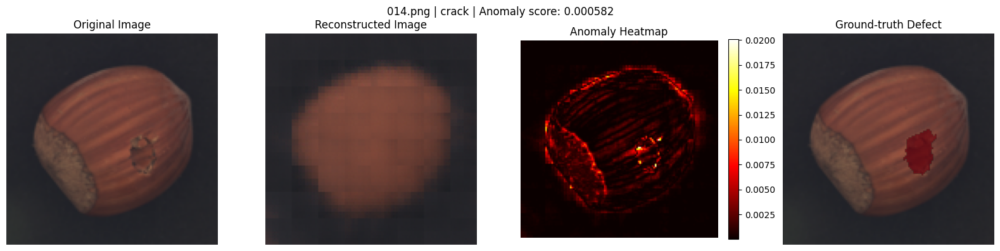

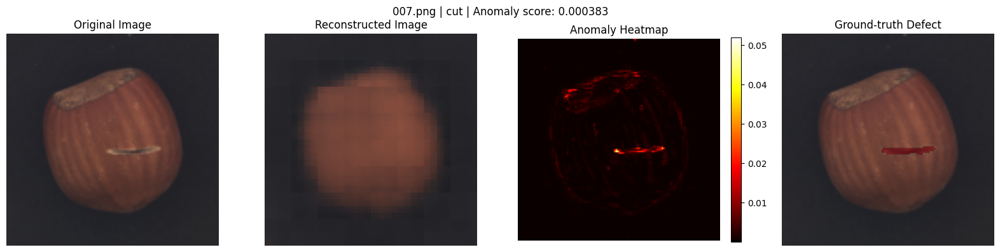

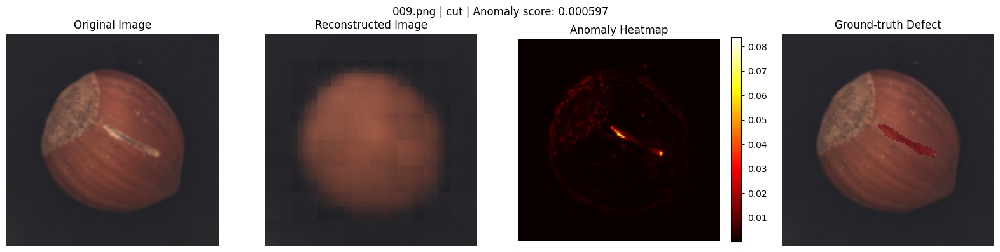

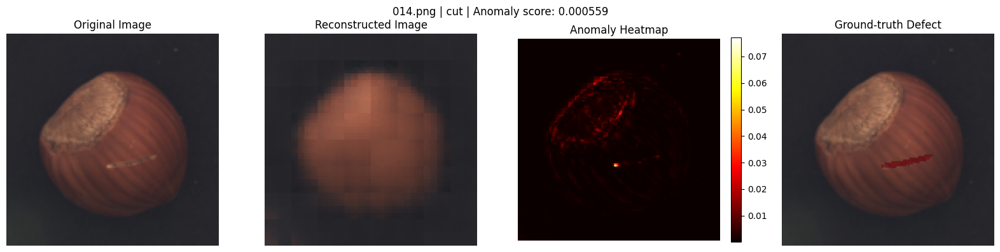

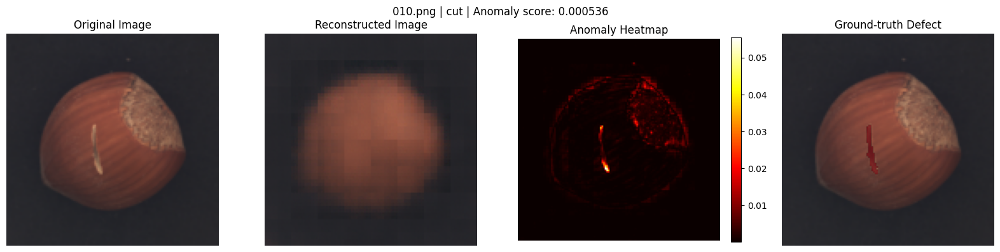

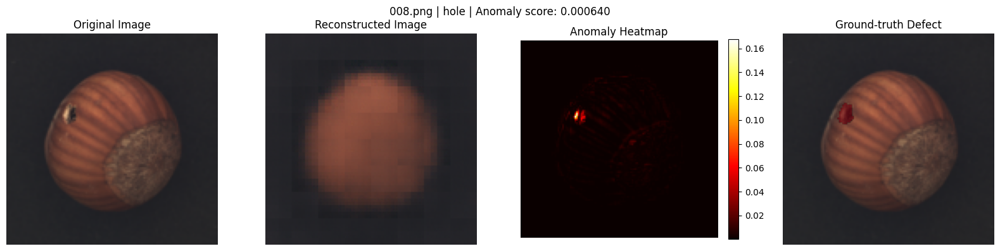

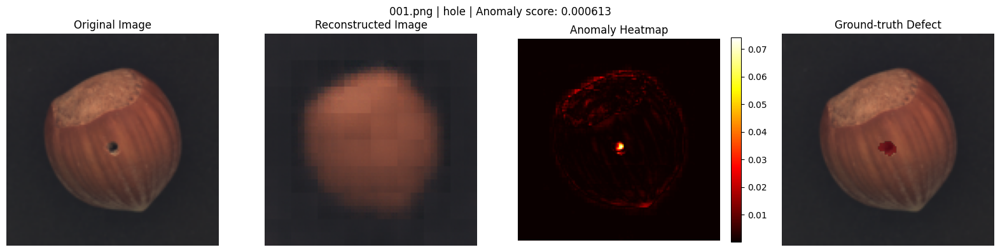

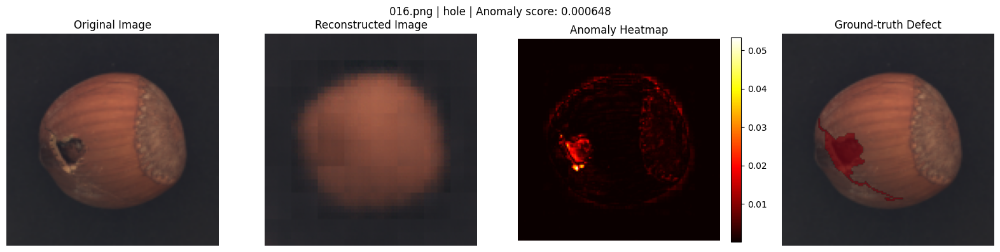

In [ ]:
show_anomaly_heatmaps(false_negatives)

In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

import numpy as np
import pandas as pd
import torch

model.eval()

all_pixel_scores = []
all_pixel_masks = []

with torch.no_grad():

    for batch in val_loader:

        images = batch["image"].to(device)
        masks = batch["mask"].to(device)

        reconstructed = model(images)

        # Pixel-wise reconstruction error
        anomaly_maps = torch.mean(
            (images - reconstructed) ** 2,
            dim=1
        )

        all_pixel_scores.append(
            anomaly_maps.cpu().numpy().ravel()
        )

        all_pixel_masks.append(
            masks.squeeze(1).cpu().numpy().ravel()
        )

# Combine all validation pixels
pixel_scores = np.concatenate(all_pixel_scores)
pixel_masks = np.concatenate(all_pixel_masks)

print("Total validation pixels:", len(pixel_scores))
print("Defective pixels:", int(pixel_masks.sum()))
print("Normal pixels:", int(len(pixel_masks) - pixel_masks.sum()))

Total validation pixels: 1540096
Defective pixels: 25305
Normal pixels: 1514791


In [ ]:
pixel_roc_auc = roc_auc_score(
    pixel_masks,
    pixel_scores
)

pixel_ap = average_precision_score(
    pixel_masks,
    pixel_scores
)

print("PIXEL-LEVEL VALIDATION PERFORMANCE")
print("----------------------------------")
print("Pixel ROC-AUC:", round(pixel_roc_auc, 4))
print("Pixel Average Precision:", round(pixel_ap, 4))

PIXEL-LEVEL VALIDATION PERFORMANCE
----------------------------------
Pixel ROC-AUC: 0.9306
Pixel Average Precision: 0.5078


In [ ]:
precision_px, recall_px, thresholds_px = precision_recall_curve(
    pixel_masks,
    pixel_scores
)

f1_px = (
    2 * precision_px[:-1] * recall_px[:-1] /
    (precision_px[:-1] + recall_px[:-1] + 1e-10)
)

best_pixel_index = np.argmax(f1_px)

best_pixel_threshold = thresholds_px[best_pixel_index]

pixel_predictions = (
    pixel_scores >= best_pixel_threshold
).astype(int)

print("Best pixel threshold:", best_pixel_threshold)
print("Pixel precision:", precision_px[best_pixel_index])
print("Pixel recall:", recall_px[best_pixel_index])
print("Pixel F1-score:", f1_px[best_pixel_index])

Best pixel threshold: 0.013013083
Pixel precision: 0.6392896108619227
Pixel recall: 0.41679509978265167
Pixel F1-score: 0.5046049326125547


In [ ]:
intersection = np.sum(
    (pixel_predictions == 1) & (pixel_masks == 1)
)

union = np.sum(
    (pixel_predictions == 1) | (pixel_masks == 1)
)

dice = (
    2 * intersection /
    (np.sum(pixel_predictions) + np.sum(pixel_masks) + 1e-10)
)

iou = intersection / (union + 1e-10)

print("\nPIXEL-LEVEL LOCALISATION")
print("------------------------")
print("Dice coefficient:", round(dice, 4))
print("Intersection over Union:", round(iou, 4))


PIXEL-LEVEL LOCALISATION
------------------------
Dice coefficient: 0.5046
Intersection over Union: 0.3374


In [ ]:
experiment_1_results = {
    "Model": "CNN Autoencoder",
    "Training Images": 313,
    "Validation Images": 94,
    "Epochs": 30,
    "Best Validation Loss": 0.0006813,
    "Image ROC-AUC": 0.8073,
    "Image Average Precision": 0.7893,
    "Image Precision": 0.6923,
    "Image Recall": 0.7714,
    "Image F1": 0.7297,
    "Pixel ROC-AUC": 0.9306,
    "Pixel Average Precision": 0.5078,
    "Pixel Precision": 0.6393,
    "Pixel Recall": 0.4168,
    "Pixel F1": 0.5046,
    "Dice": 0.5046,
    "IoU": 0.3374
}

experiment_1_df = pd.DataFrame(
    [experiment_1_results]
)

experiment_1_df.to_csv(
    os.path.join(PROJECT_PATH, "experiment_1_results.csv"),
    index=False
)

experiment_1_df

,Model,Training Images,Validation Images,Epochs,Best Validation Loss,Image ROC-AUC,Image Average Precision,Image Precision,Image Recall,Image F1,Pixel ROC-AUC,Pixel Average Precision,Pixel Precision,Pixel Recall,Pixel F1,Dice,IoU
0,CNN Autoencoder,313,94,30,0.000681,0.8073,0.7893,0.6923,0.7714,0.7297,0.9306,0.5078,0.6393,0.4168,0.5046,0.5046,0.3374


In [ ]:
# Save Experiment 1 model weights
model_path = os.path.join(
    PROJECT_PATH,
    "cnn_autoencoder_experiment_1.pth"
)

torch.save(model.state_dict(), model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: /content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project/cnn_autoencoder_experiment_1.pth


In [ ]:
experiment_1_config = {
    "architecture": "CNN Autoencoder",
    "input_size": 128,
    "batch_size": 8,
    "epochs": 30,
    "learning_rate": 0.001,
    "optimizer": "Adam",
    "loss_function": "MSE",
    "threshold": 0.0007773775,
    "pixel_threshold": 0.013013083,
    "random_seed": 42
}

import json

with open(
    os.path.join(PROJECT_PATH, "experiment_1_config.json"),
    "w"
) as f:
    json.dump(experiment_1_config, f, indent=4)

print("Experiment configuration saved!")

Experiment configuration saved!


In [44]:
class CNN_Autoencoder_V2(nn.Module):

    def __init__(self):
        super(CNN_Autoencoder_V2, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                128, 64, kernel_size=2, stride=2
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                64, 32, kernel_size=2, stride=2
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 3, kernel_size=2, stride=2
            ),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [45]:
model_v2 = CNN_Autoencoder_V2().to(device)

total_parameters = sum(
    p.numel() for p in model_v2.parameters()
    if p.requires_grad
)

print("Experiment 2: CNN Autoencoder V2")
print("--------------------------------")
print("Device:", device)
print("Trainable parameters:", total_parameters)

# Test the output dimensions
sample = torch.randn(1, 3, 128, 128).to(device)

with torch.no_grad():
    output = model_v2(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)

Experiment 2: CNN Autoencoder V2
--------------------------------
Device: cpu
Trainable parameters: 134691
Input shape: torch.Size([1, 3, 128, 128])
Output shape: torch.Size([1, 3, 128, 128])


In [ ]:
# Experiment 2: Training configuration

criterion_v2 = nn.MSELoss()

optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(),
    lr=0.001
)

num_epochs_v2 = 30
patience_v2 = 5

train_losses_v2 = []
val_losses_v2 = []

best_val_loss_v2 = float("inf")
best_epoch_v2 = 0
epochs_without_improvement_v2 = 0

print("Experiment 2 training configuration ready.")
print("Epochs:", num_epochs_v2)
print("Learning rate: 0.001")
print("Batch size: 8")
print("Optimizer: Adam")
print("Loss function: MSE")

Experiment 2 training configuration ready.
Epochs: 30
Learning rate: 0.001
Batch size: 8
Optimizer: Adam
Loss function: MSE


In [ ]:
for epoch in range(num_epochs_v2):

    # Training
    model_v2.train()
    running_train_loss = 0.0

    for batch in train_loader:
        images = batch["image"].to(device)

        optimizer_v2.zero_grad()

        reconstructed = model_v2(images)
        loss = criterion_v2(reconstructed, images)

        loss.backward()
        optimizer_v2.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses_v2.append(epoch_train_loss)

    # Validation using normal images only
    model_v2.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch in normal_val_loader:
            images = batch["image"].to(device)

            reconstructed = model_v2(images)
            loss = criterion_v2(reconstructed, images)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(normal_val_loader)
    val_losses_v2.append(epoch_val_loss)

    # Early stopping
    if epoch_val_loss < best_val_loss_v2:
        best_val_loss_v2 = epoch_val_loss
        best_epoch_v2 = epoch + 1
        epochs_without_improvement_v2 = 0

        torch.save(
            model_v2.state_dict(),
            os.path.join(PROJECT_PATH, "cnn_autoencoder_experiment_2.pth")
        )

    else:
        epochs_without_improvement_v2 += 1

    print(
        f"Epoch [{epoch+1}/{num_epochs_v2}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f}"
    )

    if epochs_without_improvement_v2 >= patience_v2:
        print("Early stopping triggered.")
        break

# Restore the best model
model_v2.load_state_dict(
    torch.load(
        os.path.join(PROJECT_PATH, "cnn_autoencoder_experiment_2.pth"),
        map_location=device
    )
)

print("\nExperiment 2 training completed.")
print("Best epoch:", best_epoch_v2)
print("Best validation loss:", best_val_loss_v2)

Epoch [1/30] Train Loss: 0.059696 Val Loss: 0.020614
Epoch [2/30] Train Loss: 0.008647 Val Loss: 0.005520
Epoch [3/30] Train Loss: 0.005031 Val Loss: 0.004544
Epoch [4/30] Train Loss: 0.003094 Val Loss: 0.001930
Epoch [5/30] Train Loss: 0.001441 Val Loss: 0.001180
Epoch [6/30] Train Loss: 0.001052 Val Loss: 0.001009
Epoch [7/30] Train Loss: 0.000890 Val Loss: 0.000833
Epoch [8/30] Train Loss: 0.000756 Val Loss: 0.000713
Epoch [9/30] Train Loss: 0.000647 Val Loss: 0.000613
Epoch [10/30] Train Loss: 0.000569 Val Loss: 0.000565
Epoch [11/30] Train Loss: 0.000530 Val Loss: 0.000555
Epoch [12/30] Train Loss: 0.000502 Val Loss: 0.000513
Epoch [13/30] Train Loss: 0.000493 Val Loss: 0.000548
Epoch [14/30] Train Loss: 0.000476 Val Loss: 0.000474
Epoch [15/30] Train Loss: 0.000456 Val Loss: 0.000448
Epoch [16/30] Train Loss: 0.000432 Val Loss: 0.000432
Epoch [17/30] Train Loss: 0.000422 Val Loss: 0.000458
Epoch [18/30] Train Loss: 0.000424 Val Loss: 0.000413
Epoch [19/30] Train Loss: 0.000401 Va

In [ ]:
import numpy as np
import pandas as pd
import torch

model_v2.eval()

val_results_v2 = []

with torch.no_grad():
    for batch in val_loader:

        images = batch["image"].to(device)
        reconstructed = model_v2(images)

        # Calculate pixel-wise reconstruction errors
        pixel_errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=1
        )

        # Average pixel error for each image
        anomaly_scores = pixel_errors.mean(dim=(1, 2))

        for i in range(len(images)):
            val_results_v2.append({
                "filename": batch["filename"][i],
                "category": batch["category"][i],
                "label": int(batch["label"][i]),
                "anomaly_score": anomaly_scores[i].item()
            })

# Convert results into a DataFrame
val_results_v2 = pd.DataFrame(val_results_v2)

print("Experiment 2 validation results:")
display(val_results_v2.head())

print("\nNumber of validation images:", len(val_results_v2))
print("\nImages by category:")
display(val_results_v2["category"].value_counts())

print("\nAverage anomaly score by category:")
display(
    val_results_v2.groupby("category")["anomaly_score"]
    .agg(["count", "mean", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

Experiment 2 validation results:


,filename,category,label,anomaly_score
0,378.png,good,0,0.000235
1,073.png,good,0,0.000364
2,234.png,good,0,0.000325
3,202.png,good,0,0.000313
4,255.png,good,0,0.000360



Number of validation images: 94

Images by category:


,count
category,
good,59
crack,9
hole,9
print,9
cut,8



Average anomaly score by category:


,count,mean,std,min,max
category,,,,,
print,9,0.001885,0.001031,0.000704,0.004029
crack,9,0.001565,0.001185,0.000308,0.003761
hole,9,0.000473,0.000130,0.000332,0.000707
cut,8,0.000390,0.000123,0.000231,0.000576
good,59,0.000344,0.000121,0.000142,0.000733


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    f1_score
)

# Actual labels and anomaly scores
y_true_v2 = val_results_v2["label"].values
y_scores_v2 = val_results_v2["anomaly_score"].values

# Ranking metrics
roc_auc_v2 = roc_auc_score(y_true_v2, y_scores_v2)
average_precision_v2 = average_precision_score(
    y_true_v2, y_scores_v2
)

# Find the best threshold using validation F1
precision_v2, recall_v2, thresholds_v2 = precision_recall_curve(
    y_true_v2, y_scores_v2
)

f1_values_v2 = (
    2 * precision_v2[:-1] * recall_v2[:-1] /
    (precision_v2[:-1] + recall_v2[:-1] + 1e-10)
)

best_index_v2 = np.argmax(f1_values_v2)
best_threshold_v2 = thresholds_v2[best_index_v2]

# Predictions
y_pred_v2 = (y_scores_v2 >= best_threshold_v2).astype(int)

# Classification metrics
cm_v2 = confusion_matrix(y_true_v2, y_pred_v2)

print("EXPERIMENT 2 - IMAGE LEVEL EVALUATION")
print("--------------------------------------")
print(f"ROC-AUC: {roc_auc_v2:.4f}")
print(f"Average Precision: {average_precision_v2:.4f}")
print(f"Best Threshold: {best_threshold_v2:.8f}")
print(f"Precision: {precision_v2[best_index_v2]:.4f}")
print(f"Recall: {recall_v2[best_index_v2]:.4f}")
print(f"F1-score: {f1_values_v2[best_index_v2]:.4f}")

print("\nConfusion Matrix:")
print(cm_v2)

print("\nClassification Report:")
print(classification_report(
    y_true_v2,
    y_pred_v2,
    target_names=["Good", "Defective"]
))

EXPERIMENT 2 - IMAGE LEVEL EVALUATION
--------------------------------------
ROC-AUC: 0.8349
Average Precision: 0.8088
Best Threshold: 0.00044944
Precision: 0.7576
Recall: 0.7143
F1-score: 0.7353

Confusion Matrix:
[[51  8]
 [10 25]]

Classification Report:
              precision    recall  f1-score   support

        Good       0.84      0.86      0.85        59
   Defective       0.76      0.71      0.74        35

    accuracy                           0.81        94
   macro avg       0.80      0.79      0.79        94
weighted avg       0.81      0.81      0.81        94



In [ ]:
experiment_2_summary = {
    "Model": "CNN Autoencoder V2",
    "Parameters": 134691,
    "Epochs": 30,
    "Best Validation Loss": best_val_loss_v2,
    "Image ROC-AUC": roc_auc_v2,
    "Image Average Precision": average_precision_v2,
    "Image Precision": precision_v2[best_index_v2],
    "Image Recall": recall_v2[best_index_v2],
    "Image F1": f1_values_v2[best_index_v2],
    "Image Threshold": best_threshold_v2
}

experiment_2_df = pd.DataFrame([experiment_2_summary])

experiment_2_df.to_csv(
    os.path.join(PROJECT_PATH, "experiment_2_results.csv"),
    index=False
)

print("Experiment 2 results saved successfully.")
display(experiment_2_df)

Experiment 2 results saved successfully.


,Model,Parameters,Epochs,Best Validation Loss,Image ROC-AUC,Image Average Precision,Image Precision,Image Recall,Image F1,Image Threshold
0,CNN Autoencoder V2,134691,30,0.000348,0.834867,0.808772,0.757576,0.714286,0.735294,0.000449


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

model_v2.eval()

all_pixel_errors_v2 = []
all_pixel_masks_v2 = []

with torch.no_grad():
    for batch in val_loader:

        images = batch["image"].to(device)
        masks = batch["mask"]

        reconstructed = model_v2(images)

        # Calculate reconstruction error for each pixel
        pixel_errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=1
        )

        all_pixel_errors_v2.append(
            pixel_errors.cpu().numpy()
        )

        all_pixel_masks_v2.append(
            masks.squeeze(1).cpu().numpy()
        )

# Combine all validation images
all_pixel_errors_v2 = np.concatenate(
    all_pixel_errors_v2, axis=0
)

all_pixel_masks_v2 = np.concatenate(
    all_pixel_masks_v2, axis=0
)

# Flatten for pixel-level evaluation
y_pixel_true_v2 = all_pixel_masks_v2.flatten().astype(int)
y_pixel_scores_v2 = all_pixel_errors_v2.flatten()

print("Pixel-level evaluation data prepared.")
print("Total pixels:", len(y_pixel_true_v2))
print("Defect pixels:", np.sum(y_pixel_true_v2))
print("Normal pixels:", np.sum(y_pixel_true_v2 == 0))

Pixel-level evaluation data prepared.
Total pixels: 1540096
Defect pixels: 25305
Normal pixels: 1514791


In [ ]:
# Pixel-level ranking metrics
pixel_roc_auc_v2 = roc_auc_score(
    y_pixel_true_v2,
    y_pixel_scores_v2
)

pixel_ap_v2 = average_precision_score(
    y_pixel_true_v2,
    y_pixel_scores_v2
)

# Select threshold using validation F1
pixel_precision_curve_v2, pixel_recall_curve_v2, pixel_thresholds_v2 = (
    precision_recall_curve(
        y_pixel_true_v2,
        y_pixel_scores_v2
    )
)

pixel_f1_values_v2 = (
    2 * pixel_precision_curve_v2[:-1] *
    pixel_recall_curve_v2[:-1]
) / (
    pixel_precision_curve_v2[:-1] +
    pixel_recall_curve_v2[:-1] + 1e-10
)

best_pixel_index_v2 = np.argmax(pixel_f1_values_v2)

best_pixel_threshold_v2 = pixel_thresholds_v2[
    best_pixel_index_v2
]

# Binary pixel predictions
y_pixel_pred_v2 = (
    y_pixel_scores_v2 >= best_pixel_threshold_v2
).astype(int)

# Calculate metrics
pixel_precision_v2 = precision_score(
    y_pixel_true_v2, y_pixel_pred_v2, zero_division=0
)

pixel_recall_v2 = recall_score(
    y_pixel_true_v2, y_pixel_pred_v2, zero_division=0
)

pixel_f1_v2 = f1_score(
    y_pixel_true_v2, y_pixel_pred_v2, zero_division=0
)

# Dice and IoU
pixel_dice_v2 = pixel_f1_v2

pixel_iou_v2 = (
    pixel_dice_v2 / (2 - pixel_dice_v2)
)

# Confusion matrix
pixel_cm_v2 = confusion_matrix(
    y_pixel_true_v2,
    y_pixel_pred_v2
)

print("EXPERIMENT 2 - PIXEL LEVEL EVALUATION")
print("--------------------------------------")
print(f"Pixel ROC-AUC: {pixel_roc_auc_v2:.4f}")
print(f"Pixel Average Precision: {pixel_ap_v2:.4f}")
print(f"Best Pixel Threshold: {best_pixel_threshold_v2:.8f}")
print(f"Pixel Precision: {pixel_precision_v2:.4f}")
print(f"Pixel Recall: {pixel_recall_v2:.4f}")
print(f"Pixel F1-score: {pixel_f1_v2:.4f}")
print(f"Dice Coefficient: {pixel_dice_v2:.4f}")
print(f"IoU: {pixel_iou_v2:.4f}")

print("\nPixel-level Confusion Matrix:")
print(pixel_cm_v2)

EXPERIMENT 2 - PIXEL LEVEL EVALUATION
--------------------------------------
Pixel ROC-AUC: 0.9221
Pixel Average Precision: 0.4454
Best Pixel Threshold: 0.00752212
Pixel Precision: 0.5751
Pixel Recall: 0.3677
Pixel F1-score: 0.4486
Dice Coefficient: 0.4486
IoU: 0.2892

Pixel-level Confusion Matrix:
[[1507917    6874]
 [  16000    9305]]


In [ ]:
# Experiment 3A: Learning rate optimisation

model_v3a = CNN_Autoencoder_V2().to(device)

criterion_v3a = nn.MSELoss()

optimizer_v3a = torch.optim.Adam(
    model_v3a.parameters(),
    lr=0.0005
)

num_epochs_v3a = 30
patience_v3a = 5

train_losses_v3a = []
val_losses_v3a = []

best_val_loss_v3a = float("inf")
best_epoch_v3a = 0
epochs_without_improvement_v3a = 0

print("Experiment 3A: Learning Rate Optimisation")
print("-----------------------------------------")
print("Architecture: CNN Autoencoder V2")
print("Learning rate: 0.0005")
print("Optimizer: Adam")
print("Loss function: MSE")
print("Batch size: 8")
print("Maximum epochs:", num_epochs_v3a)

Experiment 3A: Learning Rate Optimisation
-----------------------------------------
Architecture: CNN Autoencoder V2
Learning rate: 0.0005
Optimizer: Adam
Loss function: MSE
Batch size: 8
Maximum epochs: 30


In [ ]:
for epoch in range(num_epochs_v3a):

    model_v3a.train()
    running_train_loss = 0.0

    for batch in train_loader:
        images = batch["image"].to(device)

        optimizer_v3a.zero_grad()

        reconstructed = model_v3a(images)
        loss = criterion_v3a(reconstructed, images)

        loss.backward()
        optimizer_v3a.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses_v3a.append(epoch_train_loss)

    # Validation on normal images only
    model_v3a.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch in normal_val_loader:
            images = batch["image"].to(device)

            reconstructed = model_v3a(images)
            loss = criterion_v3a(reconstructed, images)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(normal_val_loader)
    val_losses_v3a.append(epoch_val_loss)

    # Save best model
    if epoch_val_loss < best_val_loss_v3a:
        best_val_loss_v3a = epoch_val_loss
        best_epoch_v3a = epoch + 1
        epochs_without_improvement_v3a = 0

        torch.save(
            model_v3a.state_dict(),
            os.path.join(PROJECT_PATH, "cnn_autoencoder_experiment_3a.pth")
        )
    else:
        epochs_without_improvement_v3a += 1

    print(
        f"Epoch [{epoch+1}/{num_epochs_v3a}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f}"
    )

    if epochs_without_improvement_v3a >= patience_v3a:
        print("Early stopping triggered.")
        break

# Restore best weights
model_v3a.load_state_dict(
    torch.load(
        os.path.join(PROJECT_PATH, "cnn_autoencoder_experiment_3a.pth"),
        map_location=device
    )
)

print("\nExperiment 3A completed.")
print("Best epoch:", best_epoch_v3a)
print("Best validation loss:", best_val_loss_v3a)

Epoch [1/30] Train Loss: 0.074476 Val Loss: 0.030515
Epoch [2/30] Train Loss: 0.015095 Val Loss: 0.005122
Epoch [3/30] Train Loss: 0.004720 Val Loss: 0.004393
Epoch [4/30] Train Loss: 0.004070 Val Loss: 0.003854
Epoch [5/30] Train Loss: 0.003153 Val Loss: 0.002313
Epoch [6/30] Train Loss: 0.001690 Val Loss: 0.001344
Epoch [7/30] Train Loss: 0.001190 Val Loss: 0.001068
Epoch [8/30] Train Loss: 0.000978 Val Loss: 0.000935
Epoch [9/30] Train Loss: 0.000877 Val Loss: 0.000846
Epoch [10/30] Train Loss: 0.000794 Val Loss: 0.000807
Epoch [11/30] Train Loss: 0.000753 Val Loss: 0.000719
Epoch [12/30] Train Loss: 0.000686 Val Loss: 0.000663
Epoch [13/30] Train Loss: 0.000640 Val Loss: 0.000617
Epoch [14/30] Train Loss: 0.000591 Val Loss: 0.000597
Epoch [15/30] Train Loss: 0.000563 Val Loss: 0.000563
Epoch [16/30] Train Loss: 0.000535 Val Loss: 0.000525
Epoch [17/30] Train Loss: 0.000511 Val Loss: 0.000519
Epoch [18/30] Train Loss: 0.000495 Val Loss: 0.000493
Epoch [19/30] Train Loss: 0.000480 Va

In [ ]:
# Experiment 3B: Learning Rate Optimisation
# Learning rate = 0.0001

model_v3b = CNN_Autoencoder_V2().to(device)

criterion_v3b = nn.MSELoss()

optimizer_v3b = torch.optim.Adam(
    model_v3b.parameters(),
    lr=0.0001
)

num_epochs_v3b = 30
patience_v3b = 5

train_losses_v3b = []
val_losses_v3b = []

best_val_loss_v3b = float("inf")
best_epoch_v3b = 0
epochs_without_improvement_v3b = 0

print("Experiment 3B: Learning Rate Optimisation")
print("-----------------------------------------")
print("Architecture: CNN Autoencoder V2")
print("Learning rate: 0.0001")
print("Optimizer: Adam")
print("Loss function: MSE")
print("Batch size: 8")
print("Maximum epochs: 30")

Experiment 3B: Learning Rate Optimisation
-----------------------------------------
Architecture: CNN Autoencoder V2
Learning rate: 0.0001
Optimizer: Adam
Loss function: MSE
Batch size: 8
Maximum epochs: 30


In [ ]:
for epoch in range(num_epochs_v3b):

    # Training
    model_v3b.train()
    running_train_loss = 0.0

    for batch in train_loader:
        images = batch["image"].to(device)

        optimizer_v3b.zero_grad()

        reconstructed = model_v3b(images)
        loss = criterion_v3b(reconstructed, images)

        loss.backward()
        optimizer_v3b.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses_v3b.append(epoch_train_loss)

    # Validation using normal images only
    model_v3b.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch in normal_val_loader:
            images = batch["image"].to(device)

            reconstructed = model_v3b(images)
            loss = criterion_v3b(reconstructed, images)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(normal_val_loader)
    val_losses_v3b.append(epoch_val_loss)

    # Save the best model
    if epoch_val_loss < best_val_loss_v3b:
        best_val_loss_v3b = epoch_val_loss
        best_epoch_v3b = epoch + 1
        epochs_without_improvement_v3b = 0

        torch.save(
            model_v3b.state_dict(),
            os.path.join(PROJECT_PATH, "cnn_autoencoder_experiment_3b.pth")
        )

    else:
        epochs_without_improvement_v3b += 1

    print(
        f"Epoch [{epoch+1}/{num_epochs_v3b}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f}"
    )

    if epochs_without_improvement_v3b >= patience_v3b:
        print("Early stopping triggered.")
        break

# Load the best model
model_v3b.load_state_dict(
    torch.load(
        os.path.join(PROJECT_PATH, "cnn_autoencoder_experiment_3b.pth"),
        map_location=device
    )
)

print("\nExperiment 3B completed.")
print("Best epoch:", best_epoch_v3b)
print("Best validation loss:", best_val_loss_v3b)

Epoch [1/30] Train Loss: 0.069822 Val Loss: 0.067075
Epoch [2/30] Train Loss: 0.057204 Val Loss: 0.039999
Epoch [3/30] Train Loss: 0.027440 Val Loss: 0.021025
Epoch [4/30] Train Loss: 0.017083 Val Loss: 0.013902
Epoch [5/30] Train Loss: 0.010512 Val Loss: 0.007519
Epoch [6/30] Train Loss: 0.005876 Val Loss: 0.005180
Epoch [7/30] Train Loss: 0.004961 Val Loss: 0.004981
Epoch [8/30] Train Loss: 0.004802 Val Loss: 0.004745
Epoch [9/30] Train Loss: 0.004473 Val Loss: 0.004270
Epoch [10/30] Train Loss: 0.003745 Val Loss: 0.003306
Epoch [11/30] Train Loss: 0.002766 Val Loss: 0.002358
Epoch [12/30] Train Loss: 0.001978 Val Loss: 0.001747
Epoch [13/30] Train Loss: 0.001527 Val Loss: 0.001434
Epoch [14/30] Train Loss: 0.001293 Val Loss: 0.001273
Epoch [15/30] Train Loss: 0.001178 Val Loss: 0.001177
Epoch [16/30] Train Loss: 0.001096 Val Loss: 0.001113
Epoch [17/30] Train Loss: 0.001047 Val Loss: 0.001061
Epoch [18/30] Train Loss: 0.001005 Val Loss: 0.001017
Epoch [19/30] Train Loss: 0.000986 Va

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

In [ ]:
# Experiment 4: Bottleneck Optimisation
# Reduced latent channels: 128 -> 64

class CNN_Autoencoder_V3(nn.Module):

    def __init__(self):
        super(CNN_Autoencoder_V3, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 64, 2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, 2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 3, 2, stride=2),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded


# Initialise model
model_v4 = CNN_Autoencoder_V3().to(device)

# Count parameters
total_params_v4 = sum(
    p.numel() for p in model_v4.parameters() if p.requires_grad
)

print("Experiment 4: Bottleneck Optimisation")
print("-------------------------------------")
print("Architecture: CNN Autoencoder V3")
print("Latent channels: 64")
print("Input shape: 3 x 128 x 128")
print("Latent shape: 64 x 16 x 16")
print("Trainable parameters:", total_params_v4)

# Verify output shape
sample = next(iter(train_loader))["image"].to(device)

with torch.no_grad():
    reconstructed = model_v4(sample)

print("Input shape:", sample.shape)
print("Output shape:", reconstructed.shape)

Experiment 4: Bottleneck Optimisation
-------------------------------------
Architecture: CNN Autoencoder V3
Latent channels: 64
Input shape: 3 x 128 x 128
Latent shape: 64 x 16 x 16
Trainable parameters: 81379
Input shape: torch.Size([8, 3, 128, 128])
Output shape: torch.Size([8, 3, 128, 128])


In [ ]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialise model
model_v4 = CNN_Autoencoder_V3().to(device)

# Loss and optimiser
criterion = nn.MSELoss()
optimizer = optim.Adam(model_v4.parameters(), lr=0.001)

# Training settings
num_epochs = 30
patience = 5

best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model_v4.state_dict())
epochs_without_improvement = 0

train_losses_v4 = []
val_losses_v4 = []

print("Starting Experiment 4: Bottleneck Optimisation")
print("Device:", device)

for epoch in range(num_epochs):

    # Training
    model_v4.train()
    running_train_loss = 0.0

    for batch in train_loader:
        images = batch["image"].to(device)

        optimizer.zero_grad()

        outputs = model_v4(images)
        loss = criterion(outputs, images)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses_v4.append(epoch_train_loss)

    # Validation using normal images only
    model_v4.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch in normal_val_loader:
            images = batch["image"].to(device)

            outputs = model_v4(images)
            loss = criterion(outputs, images)

            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(normal_val_loader.dataset)
    val_losses_v4.append(epoch_val_loss)

    # Early stopping
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(model_v4.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f}"
    )

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore best model
model_v4.load_state_dict(best_model_weights)

# Save model
model_path = os.path.join(
    PROJECT_PATH,
    "cnn_autoencoder_experiment_4.pth"
)

torch.save(model_v4.state_dict(), model_path)

print("\nExperiment 4 training completed!")
print("Best validation loss:", best_val_loss)
print("Model saved to:", model_path)

Starting Experiment 4: Bottleneck Optimisation
Device: cpu
Epoch [1/30] Train Loss: 0.078524 Val Loss: 0.028474
Epoch [2/30] Train Loss: 0.012169 Val Loss: 0.005359
Epoch [3/30] Train Loss: 0.005045 Val Loss: 0.004676
Epoch [4/30] Train Loss: 0.004331 Val Loss: 0.003661
Epoch [5/30] Train Loss: 0.002578 Val Loss: 0.001771
Epoch [6/30] Train Loss: 0.001508 Val Loss: 0.001353
Epoch [7/30] Train Loss: 0.001287 Val Loss: 0.001318
Epoch [8/30] Train Loss: 0.001204 Val Loss: 0.001160
Epoch [9/30] Train Loss: 0.001120 Val Loss: 0.001094
Epoch [10/30] Train Loss: 0.001064 Val Loss: 0.001069
Epoch [11/30] Train Loss: 0.001016 Val Loss: 0.000999
Epoch [12/30] Train Loss: 0.000971 Val Loss: 0.000954
Epoch [13/30] Train Loss: 0.000915 Val Loss: 0.000889
Epoch [14/30] Train Loss: 0.000859 Val Loss: 0.000823
Epoch [15/30] Train Loss: 0.000774 Val Loss: 0.000761
Epoch [16/30] Train Loss: 0.000702 Val Loss: 0.000666
Epoch [17/30] Train Loss: 0.000637 Val Loss: 0.000618
Epoch [18/30] Train Loss: 0.0006

In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

experiment_4_history = pd.DataFrame({
    "Epoch": range(1, len(train_losses_v4) + 1),
    "Training Loss": train_losses_v4,
    "Validation Loss": val_losses_v4
})

experiment_4_history.to_csv(
    os.path.join(PROJECT_PATH, "experiment_4_training_history.csv"),
    index=False
)

print(experiment_4_history.tail())
print("\nTraining history saved successfully!")

    Epoch  Training Loss  Validation Loss
25     26       0.000422         0.000418
26     27       0.000414         0.000408
27     28       0.000431         0.000405
28     29       0.000401         0.000399
29     30       0.000398         0.000415

Training history saved successfully!


In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import torch
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

model_v4.eval()

all_scores_v4 = []
all_labels_v4 = []

with torch.no_grad():
    for batch in val_loader:

        images = batch["image"].to(device)
        labels = batch["label"]

        reconstructed = model_v4(images)

        # Calculate image-level reconstruction error
        errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=(1, 2, 3)
        )

        all_scores_v4.extend(errors.cpu().numpy())
        all_labels_v4.extend(labels.cpu().numpy())

# Convert to arrays
all_scores_v4 = np.array(all_scores_v4)
all_labels_v4 = np.array(all_labels_v4)

# Image-level metrics
roc_auc_v4 = roc_auc_score(all_labels_v4, all_scores_v4)
ap_v4 = average_precision_score(all_labels_v4, all_scores_v4)

# Find optimal threshold using validation F1
precision, recall, thresholds = precision_recall_curve(
    all_labels_v4, all_scores_v4
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold_v4 = thresholds[best_index]

# Predictions
predictions_v4 = (
    all_scores_v4 >= best_threshold_v4
).astype(int)

# Confusion matrix
cm_v4 = confusion_matrix(all_labels_v4, predictions_v4)

# Results
print("EXPERIMENT 4: IMAGE-LEVEL EVALUATION")
print("------------------------------------")
print(f"ROC-AUC: {roc_auc_v4:.4f}")
print(f"Average Precision: {ap_v4:.4f}")
print(f"Optimal Threshold: {best_threshold_v4:.8f}")
print(f"Precision: {precision_score(all_labels_v4, predictions_v4):.4f}")
print(f"Recall: {recall_score(all_labels_v4, predictions_v4):.4f}")
print(f"F1-score: {f1_score(all_labels_v4, predictions_v4):.4f}")

print("\nConfusion Matrix:")
print(cm_v4)

print("\nClassification Report:")
print(classification_report(
    all_labels_v4,
    predictions_v4,
    target_names=["Normal", "Defective"]
))

EXPERIMENT 4: IMAGE-LEVEL EVALUATION
------------------------------------
ROC-AUC: 0.8320
Average Precision: 0.8088
Optimal Threshold: 0.00047728
Precision: 0.7500
Recall: 0.7714
F1-score: 0.7606

Confusion Matrix:
[[50  9]
 [ 8 27]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.86      0.85      0.85        59
   Defective       0.75      0.77      0.76        35

    accuracy                           0.82        94
   macro avg       0.81      0.81      0.81        94
weighted avg       0.82      0.82      0.82        94



In [ ]:
import numpy as np
import torch
import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

model_v4.eval()

all_pixel_scores_v4 = []
all_pixel_labels_v4 = []

with torch.no_grad():
    for batch in val_loader:

        images = batch["image"].to(device)
        masks = batch["mask"]

        reconstructed = model_v4(images)

        # Pixel-wise reconstruction error
        pixel_errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=1
        )

        all_pixel_scores_v4.extend(
            pixel_errors.cpu().numpy().reshape(-1)
        )

        all_pixel_labels_v4.extend(
            masks.numpy().reshape(-1)
        )

# Convert to arrays
all_pixel_scores_v4 = np.array(all_pixel_scores_v4)
all_pixel_labels_v4 = np.array(all_pixel_labels_v4)

# Pixel-level metrics
pixel_roc_auc_v4 = roc_auc_score(
    all_pixel_labels_v4,
    all_pixel_scores_v4
)

pixel_ap_v4 = average_precision_score(
    all_pixel_labels_v4,
    all_pixel_scores_v4
)

# Find optimal threshold using validation data
precision_v4, recall_v4, thresholds_v4 = precision_recall_curve(
    all_pixel_labels_v4,
    all_pixel_scores_v4
)

f1_v4 = (
    2 * precision_v4[:-1] * recall_v4[:-1] /
    (precision_v4[:-1] + recall_v4[:-1] + 1e-10)
)

best_pixel_index_v4 = np.argmax(f1_v4)
best_pixel_threshold_v4 = thresholds_v4[best_pixel_index_v4]

# Binary pixel predictions
pixel_predictions_v4 = (
    all_pixel_scores_v4 >= best_pixel_threshold_v4
).astype(int)

# Calculate Dice and IoU
tp = np.sum((pixel_predictions_v4 == 1) & (all_pixel_labels_v4 == 1))
fp = np.sum((pixel_predictions_v4 == 1) & (all_pixel_labels_v4 == 0))
fn = np.sum((pixel_predictions_v4 == 0) & (all_pixel_labels_v4 == 1))

dice_v4 = (2 * tp) / (2 * tp + fp + fn + 1e-10)
iou_v4 = tp / (tp + fp + fn + 1e-10)

pixel_precision_v4 = tp / (tp + fp + 1e-10)
pixel_recall_v4 = tp / (tp + fn + 1e-10)

# Display results
print("EXPERIMENT 4: PIXEL-LEVEL EVALUATION")
print("------------------------------------")
print(f"ROC-AUC: {pixel_roc_auc_v4:.4f}")
print(f"Average Precision: {pixel_ap_v4:.4f}")
print(f"Optimal Threshold: {best_pixel_threshold_v4:.8f}")
print(f"Precision: {pixel_precision_v4:.4f}")
print(f"Recall: {pixel_recall_v4:.4f}")
print(f"Dice Coefficient: {dice_v4:.4f}")
print(f"IoU: {iou_v4:.4f}")

print("\nPixel counts:")
print("True positives:", tp)
print("False positives:", fp)
print("False negatives:", fn)
print("Total pixels:", len(all_pixel_labels_v4))

EXPERIMENT 4: PIXEL-LEVEL EVALUATION
------------------------------------
ROC-AUC: 0.9253
Average Precision: 0.4412
Optimal Threshold: 0.00775025
Precision: 0.5415
Recall: 0.3772
Dice Coefficient: 0.4447
IoU: 0.2859

Pixel counts:
True positives: 9545
False positives: 8081
False negatives: 15760
Total pixels: 1540096


In [ ]:
experiment_4_results = pd.DataFrame([{
    "Experiment": "Experiment 4",
    "Architecture": "CNN Autoencoder V3",
    "Parameters": 81379,
    "Epochs": 30,
    "Best Validation Loss": best_val_loss,
    "Image ROC-AUC": roc_auc_v4,
    "Image AP": ap_v4,
    "Image Precision": precision_score(all_labels_v4, predictions_v4),
    "Image Recall": recall_score(all_labels_v4, predictions_v4),
    "Image F1": f1_score(all_labels_v4, predictions_v4),
    "Pixel ROC-AUC": pixel_roc_auc_v4,
    "Pixel AP": pixel_ap_v4,
    "Pixel Precision": pixel_precision_v4,
    "Pixel Recall": pixel_recall_v4,
    "Dice": dice_v4,
    "IoU": iou_v4
}])

experiment_4_results.to_csv(
    os.path.join(PROJECT_PATH, "experiment_4_results.csv"),
    index=False
)

print(experiment_4_results.T)
print("\nExperiment 4 results saved!")

                                       0
Experiment                  Experiment 4
Architecture          CNN Autoencoder V3
Parameters                         81379
Epochs                                30
Best Validation Loss            0.000399
Image ROC-AUC                   0.831961
Image AP                        0.808755
Image Precision                     0.75
Image Recall                    0.771429
Image F1                        0.760563
Pixel ROC-AUC                   0.925266
Pixel AP                        0.441163
Pixel Precision                  0.54153
Pixel Recall                    0.377198
Dice                            0.444667
IoU                             0.285898

Experiment 4 results saved!


In [ ]:
#baseline ML
import numpy as np
import torch
import torch.nn.functional as F

# Extract features from images
def extract_features(loader):
    features = []
    labels = []

    for batch in loader:
        images = batch["image"]

        # Resize to 32 x 32
        images_small = F.interpolate(
            images,
            size=(32, 32),
            mode="bilinear",
            align_corners=False
        )

        # Flatten each image
        images_flat = images_small.view(images_small.size(0), -1)

        features.append(images_flat.numpy())
        labels.extend(batch["label"].numpy())

    return np.vstack(features), np.array(labels)


# Training features: normal images only
X_train_if, y_train_if = extract_features(train_loader)

# Validation features: normal and defective images
X_val_if, y_val_if = extract_features(val_loader)


print("Training feature shape:", X_train_if.shape)
print("Validation feature shape:", X_val_if.shape)
print("Training labels:", np.unique(y_train_if, return_counts=True))
print("Validation labels:", np.unique(y_val_if, return_counts=True))

Training feature shape: (313, 3072)
Validation feature shape: (94, 3072)
Training labels: (array([0]), array([313]))
Validation labels: (array([0, 1]), array([59, 35]))


In [ ]:
from sklearn.ensemble import IsolationForest

# Initialise Isolation Forest
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# Train using normal images only
isolation_forest.fit(X_train_if)

print("Isolation Forest training completed!")

Isolation Forest training completed!


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# Generate anomaly scores (higher = more anomalous)
val_scores_if = -isolation_forest.decision_function(X_val_if)

# Calculate ranking metrics
roc_auc_if = roc_auc_score(y_val_if, val_scores_if)
ap_if = average_precision_score(y_val_if, val_scores_if)

# Find the threshold that maximises validation F1
precision_curve, recall_curve, thresholds_if = precision_recall_curve(
    y_val_if, val_scores_if
)

f1_curve = (
    2 * precision_curve[:-1] * recall_curve[:-1]
    / (precision_curve[:-1] + recall_curve[:-1] + 1e-10)
)

best_idx_if = np.argmax(f1_curve)
best_threshold_if = thresholds_if[best_idx_if]

# Classify validation images
predictions_if = (val_scores_if >= best_threshold_if).astype(int)

# Calculate classification metrics
precision_if = precision_score(y_val_if, predictions_if)
recall_if = recall_score(y_val_if, predictions_if)
f1_if = f1_score(y_val_if, predictions_if)
accuracy_if = accuracy_score(y_val_if, predictions_if)
cm_if = confusion_matrix(y_val_if, predictions_if)

print("ISOLATION FOREST — VALIDATION RESULTS")
print("-------------------------------------")
print(f"ROC-AUC:       {roc_auc_if:.4f}")
print(f"Average Precision: {ap_if:.4f}")
print(f"Threshold:     {best_threshold_if:.6f}")
print(f"Precision:     {precision_if:.4f}")
print(f"Recall:        {recall_if:.4f}")
print(f"F1-score:      {f1_if:.4f}")
print(f"Accuracy:      {accuracy_if:.4f}")

print("\nConfusion Matrix:")
print(cm_if)

print("\nClassification Report:")
print(classification_report(
    y_val_if,
    predictions_if,
    target_names=["Normal", "Defective"]
))

ISOLATION FOREST — VALIDATION RESULTS
-------------------------------------
ROC-AUC:       0.7298
Average Precision: 0.5372
Threshold:     -0.067780
Precision:     0.5800
Recall:        0.8286
F1-score:      0.6824
Accuracy:      0.7128

Confusion Matrix:
[[38 21]
 [ 6 29]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.86      0.64      0.74        59
   Defective       0.58      0.83      0.68        35

    accuracy                           0.71        94
   macro avg       0.72      0.74      0.71        94
weighted avg       0.76      0.71      0.72        94



In [ ]:
isolation_forest_results = pd.DataFrame([{
    "Model": "Isolation Forest",
    "Features": "32x32 flattened RGB",
    "Training Images": len(X_train_if),
    "Validation Images": len(X_val_if),
    "ROC-AUC": roc_auc_if,
    "Average Precision": ap_if,
    "Threshold": best_threshold_if,
    "Precision": precision_if,
    "Recall": recall_if,
    "F1": f1_if,
    "Accuracy": accuracy_if
}])

isolation_forest_results.to_csv(
    os.path.join(PROJECT_PATH, "isolation_forest_results.csv"),
    index=False
)

print(isolation_forest_results.T)
print("\nIsolation Forest results saved!")

                                     0
Model                 Isolation Forest
Features           32x32 flattened RGB
Training Images                    313
Validation Images                   94
ROC-AUC                       0.729782
Average Precision             0.537242
Threshold                     -0.06778
Precision                         0.58
Recall                        0.828571
F1                            0.682353
Accuracy                      0.712766

Isolation Forest results saved!


In [ ]:
import os

model_path = os.path.join(
    PROJECT_PATH,
    "cnn_autoencoder_experiment_1.pth"
)

if os.path.exists(model_path):
    print("✅ Experiment 1 model found!")
    print("File:", model_path)
    print("Size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    print("❌ Experiment 1 model not found.")

✅ Experiment 1 model found!
File: /content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project/cnn_autoencoder_experiment_1.pth
Size: 0.54 MB


In [ ]:
model_exp1 = CNN_Autoencoder().to(device)

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

model_exp1.load_state_dict(checkpoint)
model_exp1.eval()

print("Experiment 1 model loaded successfully!")

Experiment 1 model loaded successfully!


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

model_exp1.eval()

test_scores_exp1 = []
test_labels_exp1 = []

with torch.no_grad():
    for batch in test_loader:
        images = batch["image"].to(device)
        labels = batch["label"].cpu().numpy()

        reconstructed = model_exp1(images)

        # Mean reconstruction error for each image
        errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=(1, 2, 3)
        )

        test_scores_exp1.extend(errors.cpu().numpy())
        test_labels_exp1.extend(labels)

test_scores_exp1 = np.array(test_scores_exp1)
test_labels_exp1 = np.array(test_labels_exp1)

# Apply the existing validation threshold
test_predictions_exp1 = (
    test_scores_exp1 >= 0.0007773775
).astype(int)

# Calculate test metrics
test_roc_auc_exp1 = roc_auc_score(
    test_labels_exp1, test_scores_exp1
)

test_ap_exp1 = average_precision_score(
    test_labels_exp1, test_scores_exp1
)

test_precision_exp1 = precision_score(
    test_labels_exp1, test_predictions_exp1
)

test_recall_exp1 = recall_score(
    test_labels_exp1, test_predictions_exp1
)

test_f1_exp1 = f1_score(
    test_labels_exp1, test_predictions_exp1
)

test_accuracy_exp1 = accuracy_score(
    test_labels_exp1, test_predictions_exp1
)

test_cm_exp1 = confusion_matrix(
    test_labels_exp1, test_predictions_exp1
)

print("EXPERIMENT 1 — FINAL TEST RESULTS")
print("---------------------------------")
print(f"ROC-AUC:   {test_roc_auc_exp1:.4f}")
print(f"AP:        {test_ap_exp1:.4f}")
print(f"Precision: {test_precision_exp1:.4f}")
print(f"Recall:    {test_recall_exp1:.4f}")
print(f"F1-score:  {test_f1_exp1:.4f}")
print(f"Accuracy:  {test_accuracy_exp1:.4f}")

print("\nConfusion Matrix:")
print(test_cm_exp1)

print("\nClassification Report:")
print(classification_report(
    test_labels_exp1,
    test_predictions_exp1,
    target_names=["Normal", "Defective"]
))

EXPERIMENT 1 — FINAL TEST RESULTS
---------------------------------
ROC-AUC:   0.7811
AP:        0.7214
Precision: 0.6364
Recall:    0.6000
F1-score:  0.6176
Accuracy:  0.7234

Confusion Matrix:
[[47 12]
 [14 21]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.77      0.80      0.78        59
   Defective       0.64      0.60      0.62        35

    accuracy                           0.72        94
   macro avg       0.70      0.70      0.70        94
weighted avg       0.72      0.72      0.72        94



In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score
)

model_exp1.eval()

test_pixel_scores = []
test_pixel_labels = []

with torch.no_grad():
    for batch in test_loader:
        images = batch["image"].to(device)
        masks = batch["mask"].cpu().numpy()

        reconstructed = model_exp1(images)

        # Pixel-level reconstruction error
        anomaly_maps = torch.mean(
            (images - reconstructed) ** 2,
            dim=1,
            keepdim=True
        )

        test_pixel_scores.extend(
            anomaly_maps.cpu().numpy().reshape(-1)
        )

        test_pixel_labels.extend(
            masks.reshape(-1)
        )

test_pixel_scores = np.array(test_pixel_scores)
test_pixel_labels = np.array(test_pixel_labels)

# Apply the validation-selected threshold
pixel_threshold_exp1 = 0.013013083

test_pixel_predictions = (
    test_pixel_scores >= pixel_threshold_exp1
).astype(int)

# Calculate metrics
test_pixel_roc_auc = roc_auc_score(
    test_pixel_labels, test_pixel_scores
)

test_pixel_ap = average_precision_score(
    test_pixel_labels, test_pixel_scores
)

test_pixel_precision = precision_score(
    test_pixel_labels, test_pixel_predictions,
    zero_division=0
)

test_pixel_recall = recall_score(
    test_pixel_labels, test_pixel_predictions,
    zero_division=0
)

test_pixel_dice = (
    2 * test_pixel_precision * test_pixel_recall
    / (test_pixel_precision + test_pixel_recall + 1e-10)
)

test_pixel_iou = (
    test_pixel_dice / (2 - test_pixel_dice)
)

print("EXPERIMENT 1 — PIXEL-LEVEL TEST RESULTS")
print("---------------------------------------")
print(f"Pixel ROC-AUC: {test_pixel_roc_auc:.4f}")
print(f"Pixel AP:      {test_pixel_ap:.4f}")
print(f"Precision:     {test_pixel_precision:.4f}")
print(f"Recall:        {test_pixel_recall:.4f}")
print(f"Dice:          {test_pixel_dice:.4f}")
print(f"IoU:           {test_pixel_iou:.4f}")

EXPERIMENT 1 — PIXEL-LEVEL TEST RESULTS
---------------------------------------
Pixel ROC-AUC: 0.9325
Pixel AP:      0.4602
Precision:     0.5084
Recall:        0.4229
Dice:          0.4617
IoU:           0.3002


In [ ]:
final_test_results = pd.DataFrame([{
    "Model": "CNN Autoencoder Experiment 1",
    "Image ROC-AUC": test_roc_auc_exp1,
    "Image AP": test_ap_exp1,
    "Image Precision": test_precision_exp1,
    "Image Recall": test_recall_exp1,
    "Image F1": test_f1_exp1,
    "Image Accuracy": test_accuracy_exp1,
    "Pixel ROC-AUC": test_pixel_roc_auc,
    "Pixel AP": test_pixel_ap,
    "Pixel Precision": test_pixel_precision,
    "Pixel Recall": test_pixel_recall,
    "Dice": test_pixel_dice,
    "IoU": test_pixel_iou
}])

final_test_results.to_csv(
    os.path.join(PROJECT_PATH, "final_test_results.csv"),
    index=False
)

print(final_test_results.T)
print("\nFinal test results saved!")

                                            0
Model            CNN Autoencoder Experiment 1
Image ROC-AUC                        0.781114
Image AP                              0.72137
Image Precision                      0.636364
Image Recall                              0.6
Image F1                             0.617647
Image Accuracy                       0.723404
Pixel ROC-AUC                        0.932488
Pixel AP                             0.460178
Pixel Precision                      0.508417
Pixel Recall                         0.422879
Dice                                  0.46172
IoU                                  0.300153

Final test results saved!


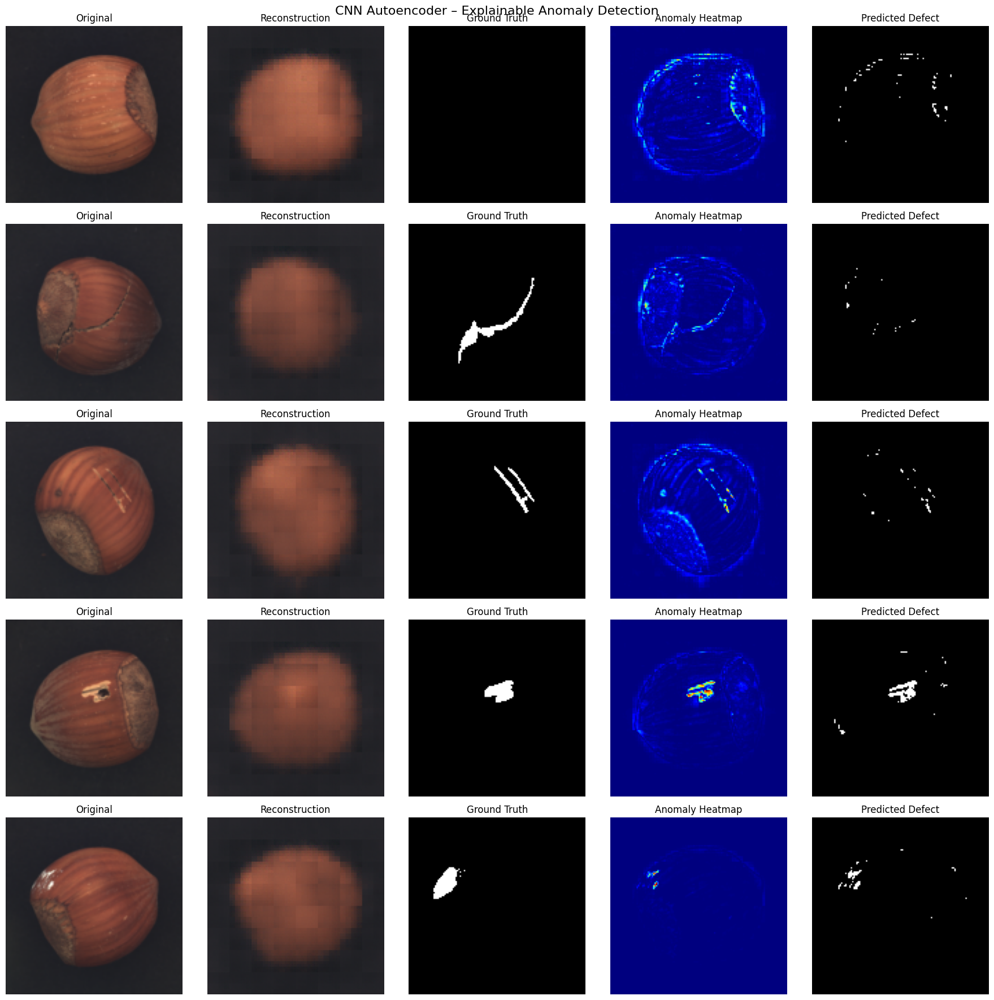

In [ ]:
#AI
import matplotlib.pyplot as plt
import os
import numpy as np
import torch

model_exp1.eval()

selected_samples = {}

with torch.no_grad():
    for batch in test_loader:

        images = batch["image"].to(device)
        masks = batch["mask"].cpu().numpy()
        labels = batch["label"].numpy()
        categories = batch["category"]
        filenames = batch["filename"]

        reconstructed = model_exp1(images)

        anomaly_maps = torch.mean(
            (images - reconstructed) ** 2,
            dim=1
        ).cpu().numpy()

        for i in range(len(images)):
            category = categories[i]

            if category not in selected_samples:
                selected_samples[category] = {
                    "original": images[i].cpu().permute(1, 2, 0).numpy(),
                    "reconstructed": reconstructed[i].cpu().permute(1, 2, 0).numpy(),
                    "mask": masks[i][0],
                    "anomaly_map": anomaly_maps[i],
                    "label": labels[i],
                    "filename": filenames[i]
                }

        if len(selected_samples) >= 5:
            break


# Display selected examples
fig, axes = plt.subplots(
    5, 5,
    figsize=(18, 18)
)

for row, category in enumerate(
    ["good", "crack", "cut", "hole", "print"]
):

    sample = selected_samples[category]

    predicted_mask = (
        sample["anomaly_map"] >= 0.013013083
    ).astype(int)

    axes[row, 0].imshow(sample["original"])
    axes[row, 0].set_title("Original")

    axes[row, 1].imshow(sample["reconstructed"])
    axes[row, 1].set_title("Reconstruction")

    axes[row, 2].imshow(sample["mask"], cmap="gray")
    axes[row, 2].set_title("Ground Truth")

    axes[row, 3].imshow(
        sample["anomaly_map"],
        cmap="jet"
    )
    axes[row, 3].set_title("Anomaly Heatmap")

    axes[row, 4].imshow(predicted_mask, cmap="gray")
    axes[row, 4].set_title("Predicted Defect")

    for col in range(5):
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        category.upper(),
        fontsize=12,
        rotation=90,
        labelpad=15
    )

plt.suptitle(
    "CNN Autoencoder – Explainable Anomaly Detection",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "final_test_xai_heatmaps.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

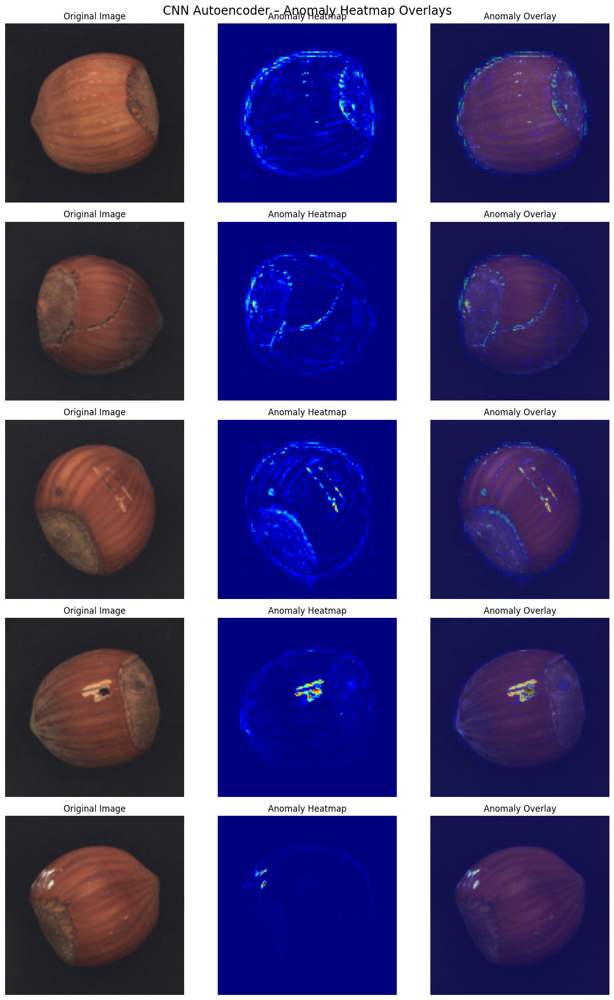

Overlay visualisation saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os

categories_to_show = ["good", "crack", "cut", "hole", "print"]

fig, axes = plt.subplots(
    5, 3,
    figsize=(13, 20)
)

for row, category in enumerate(categories_to_show):

    sample = selected_samples[category]

    original = sample["original"]
    anomaly_map = sample["anomaly_map"]

    # Normalise heatmap for visualisation only
    heatmap_normalised = (
        (anomaly_map - anomaly_map.min()) /
        (anomaly_map.max() - anomaly_map.min() + 1e-10)
    )

    # Original image
    axes[row, 0].imshow(original)
    axes[row, 0].set_title("Original Image")

    # Anomaly heatmap
    axes[row, 1].imshow(
        heatmap_normalised,
        cmap="jet"
    )
    axes[row, 1].set_title("Anomaly Heatmap")

    # Overlay heatmap on original image
    axes[row, 2].imshow(original)
    axes[row, 2].imshow(
        heatmap_normalised,
        cmap="jet",
        alpha=0.45
    )
    axes[row, 2].set_title("Anomaly Overlay")

    for col in range(3):
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        category.upper(),
        fontsize=12,
        labelpad=12
    )

plt.suptitle(
    "CNN Autoencoder – Anomaly Heatmap Overlays",
    fontsize=17
)

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "xai_anomaly_overlays.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Overlay visualisation saved successfully!")

In [ ]:
print(model_exp1)

CNN_Autoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(2, 2), stride=(2, 2))
    (1): ReLU()
    (2): ConvTranspose2d(64, 32, kernel_size=(2, 2), stride=(2, 2))
    (3): ReLU()
    (4): ConvTranspose2d(32, 16, kernel_size=(2, 2), strid

In [ ]:
for key, value in model_exp1.state_dict().items():
    print(key, value.shape)

encoder.0.weight torch.Size([16, 3, 3, 3])
encoder.0.bias torch.Size([16])
encoder.3.weight torch.Size([32, 16, 3, 3])
encoder.3.bias torch.Size([32])
encoder.6.weight torch.Size([64, 32, 3, 3])
encoder.6.bias torch.Size([64])
encoder.9.weight torch.Size([128, 64, 3, 3])
encoder.9.bias torch.Size([128])
decoder.0.weight torch.Size([128, 64, 2, 2])
decoder.0.bias torch.Size([64])
decoder.2.weight torch.Size([64, 32, 2, 2])
decoder.2.bias torch.Size([32])
decoder.4.weight torch.Size([32, 16, 2, 2])
decoder.4.bias torch.Size([16])
decoder.6.weight torch.Size([16, 3, 2, 2])
decoder.6.bias torch.Size([3])


In [15]:
def calculate_anomaly_scores(model, dataloader, device):

    model.eval()

    mse_scores = []
    top1_scores = []
    top5_scores = []
    labels = []

    with torch.no_grad():

        for batch in dataloader:

            images = batch["image"].to(device)
            batch_labels = batch["label"]

            reconstructions = model(images)

            # Pixel-wise reconstruction error
            error_maps = torch.mean(
                (images - reconstructions) ** 2,
                dim=1
            )

            for i in range(images.size(0)):

                errors = error_maps[i].flatten()

                # Original mean reconstruction error
                mse_scores.append(errors.mean().item())

                # Highest-error 1% of pixels
                top1_count = max(1, int(len(errors) * 0.01))
                top1_scores.append(
                    torch.topk(errors, top1_count).values.mean().item()
                )

                # Highest-error 5% of pixels
                top5_count = max(1, int(len(errors) * 0.05))
                top5_scores.append(
                    torch.topk(errors, top5_count).values.mean().item()
                )

            labels.extend(batch_labels.cpu().numpy())

    return (
        np.array(mse_scores),
        np.array(top1_scores),
        np.array(top5_scores),
        np.array(labels)
    )


mse_scores, top1_scores, top5_scores, validation_labels = (
    calculate_anomaly_scores(
        model_exp1,
        val_loader,
        device
    )
)

print("Scoring completed!")
print("MSE scores:", len(mse_scores))
print("Top 1% scores:", len(top1_scores))
print("Top 5% scores:", len(top5_scores))
print("Labels:", len(validation_labels))

Scoring completed!
MSE scores: 94
Top 1% scores: 94
Top 5% scores: 94
Labels: 94


In [16]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

scoring_methods = {
    "Original MSE": mse_scores,
    "Top 1%": top1_scores,
    "Top 5%": top5_scores
}

comparison_results = []

for method_name, scores in scoring_methods.items():

    # Ranking performance
    roc_auc = roc_auc_score(validation_labels, scores)
    avg_precision = average_precision_score(
        validation_labels, scores
    )

    # Select threshold using validation data
    precision_values, recall_values, thresholds = (
        precision_recall_curve(validation_labels, scores)
    )

    f1_values = (
        2 * precision_values[:-1] * recall_values[:-1]
        / (precision_values[:-1] + recall_values[:-1] + 1e-10)
    )

    best_index = np.argmax(f1_values)
    best_threshold = thresholds[best_index]

    predictions = (scores >= best_threshold).astype(int)

    precision = precision_score(
        validation_labels, predictions, zero_division=0
    )

    recall = recall_score(
        validation_labels, predictions, zero_division=0
    )

    f1 = f1_score(
        validation_labels, predictions, zero_division=0
    )

    accuracy = accuracy_score(
        validation_labels, predictions
    )

    cm = confusion_matrix(validation_labels, predictions)

    comparison_results.append({
        "Method": method_name,
        "ROC-AUC": roc_auc,
        "Average Precision": avg_precision,
        "Threshold": best_threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Accuracy": accuracy
    })

    print(f"\n{method_name}")
    print("---------------------------")
    print("ROC-AUC:", round(roc_auc, 4))
    print("Average Precision:", round(avg_precision, 4))
    print("Threshold:", best_threshold)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1:", round(f1, 4))
    print("Accuracy:", round(accuracy, 4))
    print("Confusion Matrix:\n", cm)


comparison_df = pd.DataFrame(comparison_results)

print("\nFINAL COMPARISON")
display(comparison_df.round(4))


Original MSE
---------------------------
ROC-AUC: 0.8073
Average Precision: 0.7893
Threshold: 0.0007773775141686201
Precision: 0.6923
Recall: 0.7714
F1: 0.7297
Accuracy: 0.7872
Confusion Matrix:
 [[47 12]
 [ 8 27]]

Top 1%
---------------------------
ROC-AUC: 0.8969
Average Precision: 0.881
Threshold: 0.019204156473279
Precision: 0.8387
Recall: 0.7429
F1: 0.7879
Accuracy: 0.8511
Confusion Matrix:
 [[54  5]
 [ 9 26]]

Top 5%
---------------------------
ROC-AUC: 0.8416
Average Precision: 0.8261
Threshold: 0.00873301737010479
Precision: 0.7812
Recall: 0.7143
F1: 0.7463
Accuracy: 0.8191
Confusion Matrix:
 [[52  7]
 [10 25]]

FINAL COMPARISON


,Method,ROC-AUC,Average Precision,Threshold,Precision,Recall,F1,Accuracy
0,Original MSE,0.8073,0.7893,0.0008,0.6923,0.7714,0.7297,0.7872
1,Top 1%,0.8969,0.8810,0.0192,0.8387,0.7429,0.7879,0.8511
2,Top 5%,0.8416,0.8261,0.0087,0.7812,0.7143,0.7463,0.8191


In [18]:
hole_index = np.where(
    manifest[
        (manifest["split"] == "validation") &
        (manifest["category"] == "hole")
    ]["filename"].values == "008.png"
)[0]

print("Hole image index:", hole_index)

Hole image index: [1]


In [19]:
idx = 1

print("Image: 008.png")
print("Actual category: Hole")
print("Actual label: Defective")

print("\nAnomaly scores:")
print("Original MSE:", mse_scores[idx])
print("Top 1%:", top1_scores[idx])
print("Top 5%:", top5_scores[idx])

print("\nPredictions:")

print(
    "Original MSE:",
    "Defective" if mse_scores[idx] >= 0.0007773775 else "Normal"
)

print(
    "Top 1%:",
    "Defective" if top1_scores[idx] >= 0.019204156473279 else "Normal"
)

print(
    "Top 5%:",
    "Defective" if top5_scores[idx] >= 0.00873301737010479 else "Normal"
)

Image: 008.png
Actual category: Hole
Actual label: Defective

Anomaly scores:
Original MSE: 0.000715585716534406
Top 1%: 0.0105830617249012
Top 5%: 0.006028484553098679

Predictions:
Original MSE: Normal
Top 1%: Normal
Top 5%: Normal


In [21]:
for batch in val_loader:
    filenames = batch["filename"]

    for i, filename in enumerate(filenames):
        if filename == "008.png":
            print("Found 008.png!")
            print("Actual label:", batch["label"][i].item())
            print("Batch position:", i)
            break

    if "008.png" in filenames:
        break

Found 008.png!
Actual label: 0
Batch position: 1


In [24]:
def calculate_anomaly_scores_with_filenames(model, dataloader, device):
    model.eval()

    mse_scores = []
    top1_scores = []
    top5_scores = []
    labels = []
    filenames = []

    with torch.no_grad():
        for batch in dataloader:
            images = batch["image"].to(device)
            reconstructions = model(images)

            error_maps = torch.mean(
                (images - reconstructions) ** 2,
                dim=1
            )

            for i in range(images.size(0)):
                errors = error_maps[i].flatten()

                mse_scores.append(errors.mean().item())

                top1_count = max(1, int(errors.numel() * 0.01))
                top5_count = max(1, int(errors.numel() * 0.05))

                top1_scores.append(
                    torch.topk(errors, top1_count).values.mean().item()
                )

                top5_scores.append(
                    torch.topk(errors, top5_count).values.mean().item()
                )

            labels.extend(batch["label"].cpu().numpy().tolist())
            filenames.extend(batch["filename"])

    return (
        np.array(mse_scores),
        np.array(top1_scores),
        np.array(top5_scores),
        np.array(labels),
        filenames
    )

In [25]:
from torch.utils.data import DataLoader

val_loader_ordered = DataLoader(
    val_loader.dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

mse_scores, top1_scores, top5_scores, validation_labels, all_filenames = (
    calculate_anomaly_scores_with_filenames(
        model_exp1, val_loader_ordered, device
    )
)

idx = all_filenames.index("008.png")

print("Filename:", all_filenames[idx])
print("Label:", validation_labels[idx])
print("Original MSE:", mse_scores[idx])
print("Top 1%:", top1_scores[idx])
print("Top 5%:", top5_scores[idx])
print("MSE prediction:", "Defective" if mse_scores[idx] >= 0.0007773775 else "Normal")
print("Top 1% prediction:", "Defective" if top1_scores[idx] >= 0.019204156473279 else "Normal")
print("Top 5% prediction:", "Defective" if top5_scores[idx] >= 0.00873301737010479 else "Normal")

Filename: 008.png
Label: 0
Original MSE: 0.0004694623639807105
Top 1%: 0.006835654377937317
Top 5%: 0.0036597358994185925
MSE prediction: Normal
Top 1% prediction: Normal
Top 5% prediction: Normal


In [28]:
# Find the actual hole/008.png sample in the ordered validation dataset

hole_idx = None

for i in range(len(val_loader_ordered.dataset)):
    sample = val_loader_ordered.dataset[i]

    if sample["filename"] == "008.png" and sample["category"] == "hole":
        hole_idx = i
        break

print("Index:", hole_idx)

if hole_idx is not None:
    print("Category:", "hole")
    print("Label:", validation_labels[hole_idx])
    print("Original MSE:", mse_scores[hole_idx])
    print("Top 1%:", top1_scores[hole_idx])
    print("Top 5%:", top5_scores[hole_idx])

    print(
        "MSE prediction:",
        "Defective" if mse_scores[hole_idx] >= 0.0007773775 else "Normal"
    )

    print(
        "Top 1% prediction:",
        "Defective" if top1_scores[hole_idx] >= 0.019204156473279 else "Normal"
    )

    print(
        "Top 5% prediction:",
        "Defective" if top5_scores[hole_idx] >= 0.00873301737010479 else "Normal"
    )

Index: 77
Category: hole
Label: 1
Original MSE: 0.0006402811850421131
Top 1%: 0.019656362012028694
Top 5%: 0.006956958677619696
MSE prediction: Normal
Top 1% prediction: Defective
Top 5% prediction: Normal


In [29]:
TOP1_THRESHOLD = 0.019204156473279

In [30]:
from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Keep test samples in a fixed order
test_loader_ordered = DataLoader(
    test_loader.dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Calculate all anomaly scores
test_mse, test_top1, test_top5, test_labels, test_filenames = (
    calculate_anomaly_scores_with_filenames(
        model_exp1,
        test_loader_ordered,
        device
    )
)

# Use the threshold selected using validation data
TOP1_THRESHOLD = 0.019204156473279

test_predictions_top1 = (
    test_top1 >= TOP1_THRESHOLD
).astype(int)

# Evaluate performance
print("TOP 1% – FINAL TEST RESULTS")
print("-" * 45)

print("ROC-AUC:", roc_auc_score(test_labels, test_top1))
print("Average Precision:", average_precision_score(test_labels, test_top1))
print("Precision:", precision_score(test_labels, test_predictions_top1))
print("Recall:", recall_score(test_labels, test_predictions_top1))
print("F1-score:", f1_score(test_labels, test_predictions_top1))
print("Accuracy:", accuracy_score(test_labels, test_predictions_top1))

print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, test_predictions_top1))

print("\nClassification Report:")
print(classification_report(
    test_labels,
    test_predictions_top1,
    target_names=["Normal", "Defective"]
))

TOP 1% – FINAL TEST RESULTS
---------------------------------------------
ROC-AUC: 0.8876513317191284
Average Precision: 0.8658607899373363
Precision: 0.8214285714285714
Recall: 0.6571428571428571
F1-score: 0.7301587301587301
Accuracy: 0.8191489361702128

Confusion Matrix:
[[54  5]
 [12 23]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.82      0.92      0.86        59
   Defective       0.82      0.66      0.73        35

    accuracy                           0.82        94
   macro avg       0.82      0.79      0.80        94
weighted avg       0.82      0.82      0.81        94



In [31]:
import pandas as pd

final_results_top1 = pd.DataFrame({
    "filename": test_filenames,
    "actual_label": test_labels,
    "anomaly_score_top1": test_top1,
    "predicted_label": test_predictions_top1
})

final_results_top1.to_csv(
    os.path.join(PROJECT_PATH, "final_test_results_top1.csv"),
    index=False
)

print("Top 1% final test results saved successfully.")

Top 1% final test results saved successfully.


In [32]:
!pip install -q transformers

In [33]:
#GenAI
import torch
import numpy as np
import pandas as pd
import time
from transformers import CLIPModel, CLIPProcessor
from PIL import Image
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# Model configuration
MODEL_NAME = "openai/clip-vit-base-patch32"

# Select device
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("Loading CLIP model...")

processor = CLIPProcessor.from_pretrained(MODEL_NAME)

clip_model = CLIPModel.from_pretrained(MODEL_NAME)
clip_model = clip_model.to(device)
clip_model.eval()

print("CLIP model loaded successfully!")

Device: cpu
Loading CLIP model...


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model loaded successfully!


In [34]:
# Inspect one validation sample
sample = val_loader.dataset[0]

print("Available fields:", sample.keys())
print("Image shape:", sample["image"].shape)
print("Image label:", sample["label"])
print("Category:", sample["category"])
print("Filename:", sample["filename"])

Available fields: dict_keys(['image', 'mask', 'label', 'category', 'filename'])
Image shape: torch.Size([3, 128, 128])
Image label: tensor(0)
Category: good
Filename: 378.png


In [35]:
prompt_experiments = {
    "Experiment 1 - Simple": [
        "a photo of a normal hazelnut",
        "a photo of a defective hazelnut"
    ],

    "Experiment 2 - Industrial": [
        "a high-quality hazelnut with a normal, intact surface",
        "a defective hazelnut with visible surface damage"
    ],

    "Experiment 3 - Detailed": [
        "a close-up photograph of a good hazelnut without cracks, cuts, holes or surface defects",
        "a close-up photograph of a defective hazelnut showing cracks, cuts, holes or surface damage"
    ]
}

for name, prompts in prompt_experiments.items():
    print(f"\n{name}")
    print("Normal:", prompts[0])
    print("Defective:", prompts[1])


Experiment 1 - Simple
Normal: a photo of a normal hazelnut
Defective: a photo of a defective hazelnut

Experiment 2 - Industrial
Normal: a high-quality hazelnut with a normal, intact surface
Defective: a defective hazelnut with visible surface damage

Experiment 3 - Detailed
Normal: a close-up photograph of a good hazelnut without cracks, cuts, holes or surface defects
Defective: a close-up photograph of a defective hazelnut showing cracks, cuts, holes or surface damage


In [36]:
from torch.utils.data import DataLoader

def evaluate_clip_prompts(dataset, prompts, batch_size=8):

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    all_scores = []
    all_labels = []
    all_filenames = []
    all_categories = []

    start_time = time.time()

    with torch.no_grad():

        for batch in loader:

            images = batch["image"]

            # Convert tensors into PIL images
            pil_images = [
                Image.fromarray(
                    (img.permute(1, 2, 0).numpy() * 255)
                    .clip(0, 255)
                    .astype(np.uint8)
                )
                for img in images
            ]

            # Prepare images and text for CLIP
            inputs = processor(
                text=prompts,
                images=pil_images,
                return_tensors="pt",
                padding=True
            ).to(device)

            # Calculate image-text similarities
            outputs = clip_model(**inputs)

            # Convert similarities into class probabilities
            probabilities = outputs.logits_per_image.softmax(dim=1)

            # Probability of defective class
            defective_scores = probabilities[:, 1]

            all_scores.extend(defective_scores.cpu().numpy())
            all_labels.extend(batch["label"].numpy())
            all_filenames.extend(batch["filename"])
            all_categories.extend(batch["category"])

    inference_time = time.time() - start_time

    return {
        "scores": np.array(all_scores),
        "labels": np.array(all_labels),
        "filenames": all_filenames,
        "categories": all_categories,
        "inference_time": inference_time
    }

print("CLIP prediction function created successfully!")

CLIP prediction function created successfully!


In [37]:
clip_validation_results = {}

for experiment_name, prompts in prompt_experiments.items():

    print(f"\nEvaluating {experiment_name}...")

    results = evaluate_clip_prompts(
        val_loader.dataset,
        prompts
    )

    clip_validation_results[experiment_name] = results

    print("Images evaluated:", len(results["labels"]))
    print("Inference time:", round(results["inference_time"], 2), "seconds")
    print("ROC-AUC:", round(
        roc_auc_score(results["labels"], results["scores"]), 4
    ))
    print("Average Precision:", round(
        average_precision_score(results["labels"], results["scores"]), 4
    ))

print("\nAll validation prompt experiments completed!")


Evaluating Experiment 1 - Simple...
Images evaluated: 94
Inference time: 67.1 seconds
ROC-AUC: 0.5516
Average Precision: 0.4725

Evaluating Experiment 2 - Industrial...
Images evaluated: 94
Inference time: 43.0 seconds
ROC-AUC: 0.8257
Average Precision: 0.7948

Evaluating Experiment 3 - Detailed...
Images evaluated: 94
Inference time: 25.81 seconds
ROC-AUC: 0.8833
Average Precision: 0.8507

All validation prompt experiments completed!


In [38]:
from sklearn.metrics import precision_recall_curve

threshold_results = []

for experiment_name, results in clip_validation_results.items():

    y_true = results["labels"]
    y_scores = results["scores"]

    precision, recall, thresholds = precision_recall_curve(
        y_true, y_scores
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_index = np.argmax(f1_scores)

    best_threshold = thresholds[best_index]

    threshold_results.append({
        "Experiment": experiment_name,
        "Best Threshold": best_threshold,
        "Precision": precision[best_index],
        "Recall": recall[best_index],
        "F1 Score": f1_scores[best_index],
        "ROC-AUC": roc_auc_score(y_true, y_scores),
        "Average Precision": average_precision_score(
            y_true, y_scores
        )
    })

clip_threshold_df = pd.DataFrame(threshold_results)

display(
    clip_threshold_df.round(4)
)

,Experiment,Best Threshold,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Experiment 1 - Simple,0.2768,0.3864,0.9714,0.5528,0.5516,0.4725
1,Experiment 2 - Industrial,0.5194,0.8065,0.7143,0.7576,0.8257,0.7948
2,Experiment 3 - Detailed,0.4252,0.7750,0.8857,0.8267,0.8833,0.8507


In [39]:
# Select the final configuration
selected_experiment = "Experiment 3 - Detailed"

selected_prompts = prompt_experiments[selected_experiment]

CLIP_THRESHOLD = 0.4252

print("Selected model:", MODEL_NAME)
print("Selected prompts:", selected_experiment)
print("Frozen threshold:", CLIP_THRESHOLD)

# Evaluate on held-out test data
print("\nEvaluating CLIP on final test dataset...")

clip_test_results = evaluate_clip_prompts(
    test_loader.dataset,
    selected_prompts
)

y_test = clip_test_results["labels"]
y_scores = clip_test_results["scores"]

y_pred = (y_scores >= CLIP_THRESHOLD).astype(int)

# Calculate metrics
clip_test_metrics = {
    "ROC-AUC": roc_auc_score(y_test, y_scores),
    "Average Precision": average_precision_score(y_test, y_scores),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "Accuracy": accuracy_score(y_test, y_pred)
}

print("\nCLIP FINAL TEST RESULTS")

for metric, value in clip_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nInference Time:",
      round(clip_test_results["inference_time"], 2), "seconds")

Selected model: openai/clip-vit-base-patch32
Selected prompts: Experiment 3 - Detailed
Frozen threshold: 0.4252

Evaluating CLIP on final test dataset...

CLIP FINAL TEST RESULTS
ROC-AUC: 0.9201
Average Precision: 0.8969
Precision: 0.7045
Recall: 0.8857
F1-score: 0.7848
Accuracy: 0.8191

Confusion Matrix:
[[46 13]
 [ 4 31]]

Inference Time: 54.02 seconds


In [40]:
# Create detailed test results
clip_test_df = pd.DataFrame({
    "filename": clip_test_results["filenames"],
    "category": clip_test_results["categories"],
    "actual_label": y_test,
    "anomaly_score": y_scores,
    "predicted_label": y_pred
})

# Save predictions
clip_test_path = os.path.join(
    PROJECT_PATH,
    "clip_final_test_predictions.csv"
)

clip_test_df.to_csv(clip_test_path, index=False)

# Save metrics
clip_metrics_df = pd.DataFrame(
    [clip_test_metrics]
)

clip_metrics_path = os.path.join(
    PROJECT_PATH,
    "clip_final_test_metrics.csv"
)

clip_metrics_df.to_csv(clip_metrics_path, index=False)

print("CLIP test predictions saved:", clip_test_path)
print("CLIP test metrics saved:", clip_metrics_path)

CLIP test predictions saved: /content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project/clip_final_test_predictions.csv
CLIP test metrics saved: /content/drive/MyDrive/MSc_Data_Science/ANN_Hazelnut_Project/clip_final_test_metrics.csv


In [41]:
import time
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader

# Same test dataset and batch size
benchmark_loader = DataLoader(
    test_loader.dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# -----------------------------
# CNN BENCHMARK
# -----------------------------

model_exp1.eval()
cnn_device = next(model_exp1.parameters()).device

def benchmark_cnn():

    start = time.perf_counter()

    with torch.no_grad():

        for batch in benchmark_loader:

            images = batch["image"].to(cnn_device)

            reconstruction = model_exp1(images)

            error_map = torch.mean(
                (images - reconstruction) ** 2,
                dim=1
            )

            errors = error_map.flatten(start_dim=1)

            top1_count = max(1, int(errors.shape[1] * 0.01))

            anomaly_scores = torch.topk(
                errors, top1_count, dim=1
            ).values.mean(dim=1)

    return time.perf_counter() - start


# Warm-up
benchmark_cnn()

cnn_times = [benchmark_cnn() for _ in range(3)]

# -----------------------------
# CLIP BENCHMARK
# -----------------------------

def benchmark_clip():

    result = evaluate_clip_prompts(
        test_loader.dataset,
        selected_prompts,
        batch_size=8
    )

    return result["inference_time"]


# Warm-up
benchmark_clip()

clip_times = [benchmark_clip() for _ in range(3)]

# -----------------------------
# COMPARISON
# -----------------------------

benchmark_results = pd.DataFrame({
    "Model": ["CNN Autoencoder", "CLIP"],
    "Average Inference Time (seconds)": [
        np.mean(cnn_times),
        np.mean(clip_times)
    ],
    "Average Time per Image (seconds)": [
        np.mean(cnn_times) / 94,
        np.mean(clip_times) / 94
    ]
})

display(benchmark_results.round(4))

print("CNN individual runs:", cnn_times)
print("CLIP individual runs:", clip_times)

,Model,Average Inference Time (seconds),Average Time per Image (seconds)
0,CNN Autoencoder,7.5898,0.0807
1,CLIP,25.1095,0.2671


CNN individual runs: [8.48140390000026, 6.419656479999503, 7.868242040000041]
CLIP individual runs: [25.766633987426758, 25.38795566558838, 24.174002170562744]


In [46]:
# Experiment 5: CNN Autoencoder V2 with SGD

model_v5 = CNN_Autoencoder_V2().to(device)

total_parameters_v5 = sum(
    p.numel() for p in model_v5.parameters()
    if p.requires_grad
)

print("Experiment 5: CNN Autoencoder V2 with SGD")
print("-----------------------------------------")
print("Device:", device)
print("Trainable parameters:", total_parameters_v5)

Experiment 5: CNN Autoencoder V2 with SGD
-----------------------------------------
Device: cpu
Trainable parameters: 134691


In [47]:
criterion_v5 = nn.MSELoss()

optimizer_v5 = torch.optim.SGD(
    model_v5.parameters(),
    lr=0.01,
    momentum=0.9
)

num_epochs_v5 = 30
patience_v5 = 5

train_losses_v5 = []
val_losses_v5 = []

best_val_loss_v5 = float("inf")
best_epoch_v5 = 0
epochs_without_improvement_v5 = 0

In [48]:
for epoch in range(num_epochs_v5):

    model_v5.train()
    running_train_loss = 0.0

    for batch in train_loader:
        images = batch["image"].to(device)

        optimizer_v5.zero_grad()
        reconstructed = model_v5(images)
        loss = criterion_v5(reconstructed, images)

        loss.backward()
        optimizer_v5.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses_v5.append(epoch_train_loss)

    model_v5.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch in normal_val_loader:
            images = batch["image"].to(device)
            reconstructed = model_v5(images)
            loss = criterion_v5(reconstructed, images)
            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(normal_val_loader)
    val_losses_v5.append(epoch_val_loss)

    if epoch_val_loss < best_val_loss_v5:
        best_val_loss_v5 = epoch_val_loss
        best_epoch_v5 = epoch + 1
        epochs_without_improvement_v5 = 0

        torch.save(
            model_v5.state_dict(),
            os.path.join(PROJECT_PATH, "cnn_autoencoder_experiment_5_sgd.pth")
        )

    else:
        epochs_without_improvement_v5 += 1

    print(
        f"Epoch [{epoch+1}/{num_epochs_v5}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f}"
    )

    if epochs_without_improvement_v5 >= patience_v5:
        print("Early stopping triggered.")
        break

# Load the best saved model
model_v5.load_state_dict(
    torch.load(
        os.path.join(PROJECT_PATH, "cnn_autoencoder_experiment_5_sgd.pth"),
        map_location=device
    )
)

print("\nExperiment 5 completed.")
print(f"Best epoch: {best_epoch_v5}")
print(f"Best validation loss: {best_val_loss_v5:.8f}")

Epoch [1/30] Train Loss: 0.096491 Val Loss: 0.081777
Epoch [2/30] Train Loss: 0.070205 Val Loss: 0.059124
Epoch [3/30] Train Loss: 0.051357 Val Loss: 0.044286
Epoch [4/30] Train Loss: 0.039057 Val Loss: 0.034622
Epoch [5/30] Train Loss: 0.031221 Val Loss: 0.028196
Epoch [6/30] Train Loss: 0.025808 Val Loss: 0.023785
Epoch [7/30] Train Loss: 0.022119 Val Loss: 0.020743
Epoch [8/30] Train Loss: 0.019584 Val Loss: 0.018574
Epoch [9/30] Train Loss: 0.017819 Val Loss: 0.016989
Epoch [10/30] Train Loss: 0.016313 Val Loss: 0.015843
Epoch [11/30] Train Loss: 0.015201 Val Loss: 0.014985
Epoch [12/30] Train Loss: 0.014464 Val Loss: 0.014328
Epoch [13/30] Train Loss: 0.013954 Val Loss: 0.013819
Epoch [14/30] Train Loss: 0.013472 Val Loss: 0.013436
Epoch [15/30] Train Loss: 0.013120 Val Loss: 0.013134
Epoch [16/30] Train Loss: 0.012832 Val Loss: 0.012895
Epoch [17/30] Train Loss: 0.012571 Val Loss: 0.012709
Epoch [18/30] Train Loss: 0.012374 Val Loss: 0.012558
Epoch [19/30] Train Loss: 0.012435 Va

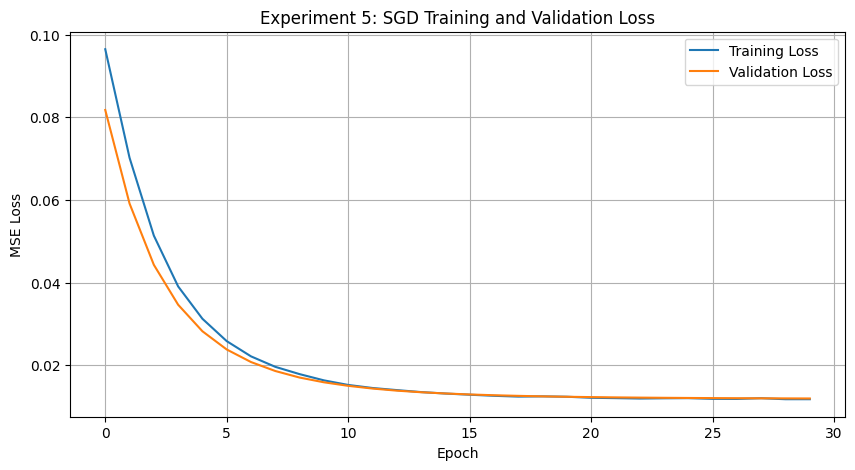

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses_v5, label="Training Loss")
plt.plot(val_losses_v5, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Experiment 5: SGD Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [50]:
# Experiment 6: SGD with a lower learning rate

model_v6 = CNN_Autoencoder_V2().to(device)

criterion_v6 = nn.MSELoss()

optimizer_v6 = torch.optim.SGD(
    model_v6.parameters(),
    lr=0.001,
    momentum=0.9
)

num_epochs_v6 = 30
patience_v6 = 5

train_losses_v6 = []
val_losses_v6 = []

best_val_loss_v6 = float("inf")
best_epoch_v6 = 0
epochs_without_improvement_v6 = 0

print("Experiment 6: CNN Autoencoder V2 with SGD")
print("Learning rate: 0.001")
print("Momentum: 0.9")
print("Device:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model_v6.parameters() if p.requires_grad)
)

Experiment 6: CNN Autoencoder V2 with SGD
Learning rate: 0.001
Momentum: 0.9
Device: cpu
Trainable parameters: 134691


In [51]:
for epoch in range(num_epochs_v6):

    model_v6.train()
    running_train_loss = 0.0

    for batch in train_loader:
        images = batch["image"].to(device)

        optimizer_v6.zero_grad()
        reconstructed = model_v6(images)
        loss = criterion_v6(reconstructed, images)

        loss.backward()
        optimizer_v6.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses_v6.append(epoch_train_loss)

    model_v6.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch in normal_val_loader:
            images = batch["image"].to(device)
            reconstructed = model_v6(images)
            loss = criterion_v6(reconstructed, images)
            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(normal_val_loader)
    val_losses_v6.append(epoch_val_loss)

    if epoch_val_loss < best_val_loss_v6:
        best_val_loss_v6 = epoch_val_loss
        best_epoch_v6 = epoch + 1
        epochs_without_improvement_v6 = 0

        torch.save(
            model_v6.state_dict(),
            os.path.join(
                PROJECT_PATH,
                "cnn_autoencoder_experiment_6_sgd_lr001.pth"
            )
        )
    else:
        epochs_without_improvement_v6 += 1

    print(
        f"Epoch [{epoch+1}/{num_epochs_v6}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f}"
    )

    if epochs_without_improvement_v6 >= patience_v6:
        print("Early stopping triggered.")
        break

model_v6.load_state_dict(
    torch.load(
        os.path.join(
            PROJECT_PATH,
            "cnn_autoencoder_experiment_6_sgd_lr001.pth"
        ),
        map_location=device
    )
)

print("\nExperiment 6 completed.")
print(f"Best epoch: {best_epoch_v6}")
print(f"Best validation loss: {best_val_loss_v6:.8f}")

Epoch [1/30] Train Loss: 0.118285 Val Loss: 0.116380
Epoch [2/30] Train Loss: 0.114802 Val Loss: 0.112773
Epoch [3/30] Train Loss: 0.110983 Val Loss: 0.109276
Epoch [4/30] Train Loss: 0.107768 Val Loss: 0.105892
Epoch [5/30] Train Loss: 0.104435 Val Loss: 0.102624
Epoch [6/30] Train Loss: 0.100991 Val Loss: 0.099471
Epoch [7/30] Train Loss: 0.098067 Val Loss: 0.096427
Epoch [8/30] Train Loss: 0.094874 Val Loss: 0.093496
Epoch [9/30] Train Loss: 0.092283 Val Loss: 0.090669
Epoch [10/30] Train Loss: 0.089490 Val Loss: 0.087931
Epoch [11/30] Train Loss: 0.086767 Val Loss: 0.085295
Epoch [12/30] Train Loss: 0.084218 Val Loss: 0.082752
Epoch [13/30] Train Loss: 0.081723 Val Loss: 0.080299
Epoch [14/30] Train Loss: 0.079008 Val Loss: 0.077935
Epoch [15/30] Train Loss: 0.077112 Val Loss: 0.075668
Epoch [16/30] Train Loss: 0.074819 Val Loss: 0.073473
Epoch [17/30] Train Loss: 0.072435 Val Loss: 0.071364
Epoch [18/30] Train Loss: 0.070318 Val Loss: 0.069335
Epoch [19/30] Train Loss: 0.068497 Va

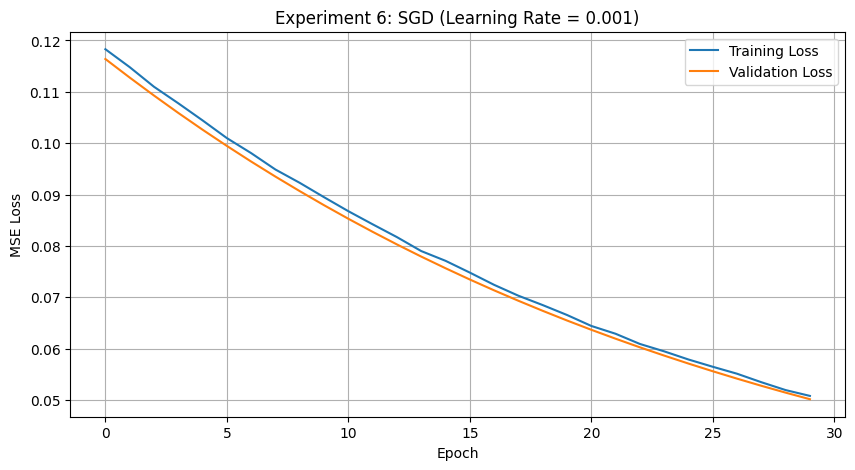

In [52]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses_v6, label="Training Loss")
plt.plot(val_losses_v6, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Experiment 6: SGD (Learning Rate = 0.001)")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(PROJECT_PATH, "experiment_6_sgd_lr001.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
# Select one normal and one defective test image

normal_index = None
defective_index = None

for i in range(len(test_loader.dataset)):
    sample = test_loader.dataset[i]

    if sample["label"] == 0 and normal_index is None:
        normal_index = i

    elif sample["label"] == 1 and defective_index is None:
        defective_index = i

    if normal_index is not None and defective_index is not None:
        break

print("Normal image index:", normal_index)
print("Defective image index:", defective_index)

normal_sample = test_loader.dataset[normal_index]
defective_sample = test_loader.dataset[defective_index]

print("\nNormal image:", normal_sample["filename"])
print("Defective image:", defective_sample["filename"])
print("Defect category:", defective_sample["category"])

Normal image index: 0
Defective image index: 59

Normal image: 193.png
Defective image: 003.png
Defect category: crack


In [54]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

model_exp1.eval()

def calculate_anomaly_score(image):
    with torch.no_grad():
        image = image.unsqueeze(0).to(device)

        reconstruction = model_exp1(image)

        error_map = torch.mean(
            (image - reconstruction) ** 2,
            dim=1
        )

        errors = error_map.flatten(start_dim=1)
        top1_count = max(1, int(errors.shape[1] * 0.01))

        score = torch.topk(
            errors, top1_count, dim=1
        ).values.mean(dim=1)

    return score.item(), error_map.squeeze().cpu().numpy()


def apply_occlusion(image, error_map, patch_size=16):

    perturbed = image.clone()

    # Find the location with the highest reconstruction error
    max_position = np.unravel_index(
        np.argmax(error_map),
        error_map.shape
    )

    y, x = max_position

    half = patch_size // 2

    y1 = max(0, y - half)
    y2 = min(image.shape[1], y + half)

    x1 = max(0, x - half)
    x2 = min(image.shape[2], x + half)

    # Calculate replacement colour from surrounding pixels
    surrounding = image[:,
        max(0, y1-4):min(image.shape[1], y2+4),
        max(0, x1-4):min(image.shape[2], x2+4)
    ]

    replacement = surrounding.mean(dim=(1, 2))

    perturbed[:, y1:y2, x1:x2] = replacement[:, None, None]

    return perturbed, (x1, y1, x2, y2)


# Test both images
samples = {
    "Normal": normal_sample,
    "Defective - Crack": defective_sample
}

occlusion_results = {}

for name, sample in samples.items():

    original_image = sample["image"]

    original_score, original_heatmap = calculate_anomaly_score(
        original_image
    )

    perturbed_image, coordinates = apply_occlusion(
        original_image,
        original_heatmap
    )

    perturbed_score, perturbed_heatmap = calculate_anomaly_score(
        perturbed_image
    )

    occlusion_results[name] = {
        "original_score": original_score,
        "perturbed_score": perturbed_score,
        "change": perturbed_score - original_score,
        "coordinates": coordinates
    }

    print(f"\n{name}")
    print(f"Original anomaly score: {original_score:.6f}")
    print(f"Perturbed anomaly score: {perturbed_score:.6f}")
    print(f"Score change: {perturbed_score - original_score:+.6f}")
    print(f"Occluded coordinates: {coordinates}")


Normal
Original anomaly score: 0.013955
Perturbed anomaly score: 0.013783
Score change: -0.000172
Occluded coordinates: (np.int64(55), np.int64(27), np.int64(71), np.int64(43))

Defective - Crack
Original anomaly score: 0.009634
Perturbed anomaly score: 0.009071
Score change: -0.000562
Occluded coordinates: (np.int64(66), np.int64(61), np.int64(82), np.int64(77))


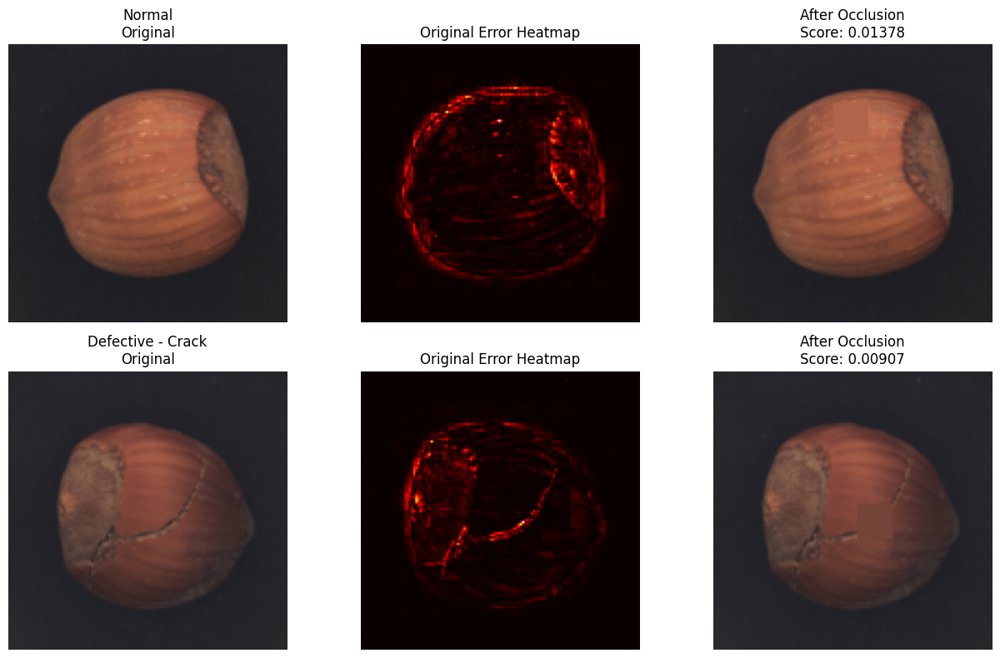

In [55]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for row, (name, sample) in enumerate(samples.items()):

    image = sample["image"]

    original_score, heatmap = calculate_anomaly_score(image)

    perturbed_image, coordinates = apply_occlusion(image, heatmap)

    perturbed_score, perturbed_heatmap = calculate_anomaly_score(
        perturbed_image
    )

    original_display = image.permute(1, 2, 0).cpu().numpy()
    perturbed_display = perturbed_image.permute(1, 2, 0).cpu().numpy()

    axes[row, 0].imshow(original_display)
    axes[row, 0].set_title(f"{name}\nOriginal")

    axes[row, 1].imshow(heatmap, cmap="hot")
    axes[row, 1].set_title("Original Error Heatmap")

    axes[row, 2].imshow(perturbed_display)
    axes[row, 2].set_title(
        f"After Occlusion\nScore: {perturbed_score:.5f}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "xai_occlusion_sanity_check.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
import pandas as pd
import os

results_path = os.path.join(
    PROJECT_PATH,
    "final_test_results_top1.csv"
)

results_df = pd.read_csv(results_path)

print("Available columns:")
print(results_df.columns.tolist())

display(results_df.head())

Available columns:
['filename', 'actual_label', 'anomaly_score_top1', 'predicted_label']


,filename,actual_label,anomaly_score_top1,predicted_label
0,193.png,0,0.013955,0
1,063.png,0,0.010007,0
2,274.png,0,0.011985,0
3,235.png,0,0.006753,0
4,373.png,0,0.014152,0


In [57]:
# Identify incorrect predictions

incorrect_predictions = results_df[
    results_df["actual_label"] != results_df["predicted_label"]
].copy()

incorrect_predictions["error_type"] = incorrect_predictions.apply(
    lambda row: "False Negative"
    if row["actual_label"] == 1
    else "False Positive",
    axis=1
)

print("Total incorrect predictions:", len(incorrect_predictions))

display(
    incorrect_predictions.sort_values(
        "anomaly_score_top1",
        ascending=False
    )
)

Total incorrect predictions: 17


,filename,actual_label,anomaly_score_top1,predicted_label,error_type
7,309.png,0,0.025936,1,False Positive
34,287.png,0,0.024516,1,False Positive
57,057.png,0,0.022146,1,False Positive
36,308.png,0,0.020662,1,False Positive
46,279.png,0,0.020434,1,False Positive
63,005.png,1,0.017478,0,False Negative
85,007.png,1,0.017460,0,False Negative
73,002.png,1,0.016994,0,False Negative
71,016.png,1,0.015225,0,False Negative
70,006.png,1,0.014725,0,False Negative


309.png | Category: good | Actual: 0 | Predicted: 1 | Score: 0.025936 | False Positive
005.png | Category: crack | Actual: 1 | Predicted: 0 | Score: 0.017478 | False Negative
003.png | Category: crack | Actual: 1 | Predicted: 0 | Score: 0.009634 | False Negative


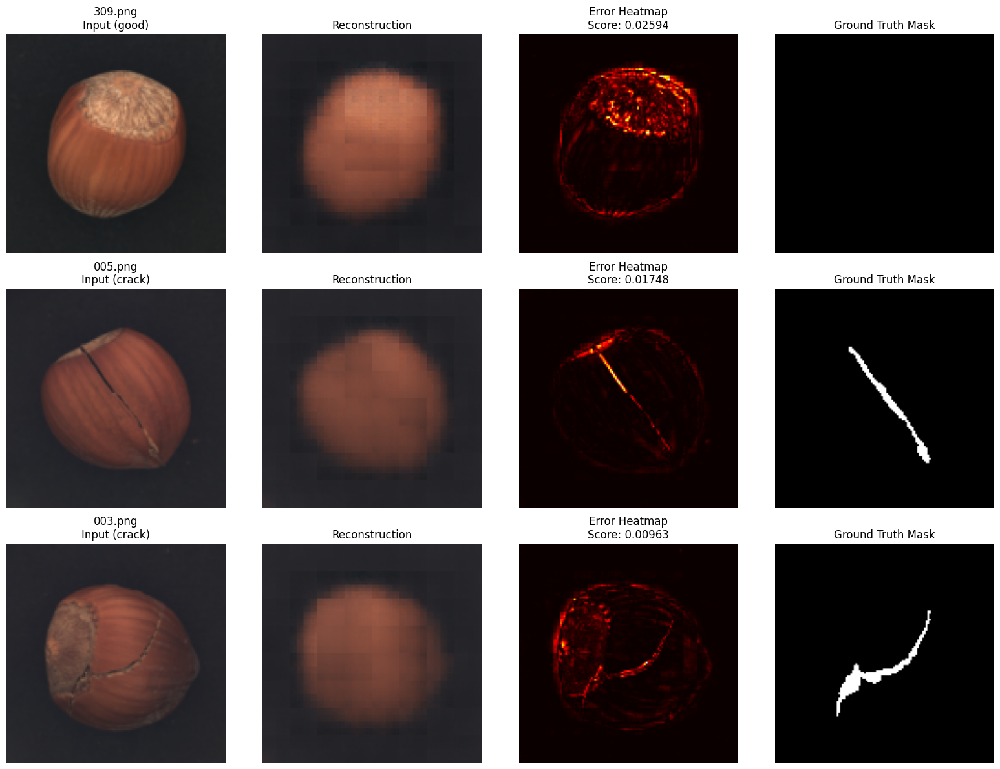

In [58]:
import matplotlib.pyplot as plt
import torch
import numpy as np

model_exp1.eval()

selected_indices = [7, 63, 59]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row, idx in enumerate(selected_indices):

    sample = test_loader.dataset[idx]

    image = sample["image"].unsqueeze(0).to(device)
    actual_label = sample["label"]
    filename = sample["filename"]
    category = sample["category"]

    with torch.no_grad():
        reconstruction = model_exp1(image)

        error_map = torch.mean(
            (image - reconstruction) ** 2,
            dim=1
        )

        errors = error_map.flatten(start_dim=1)
        top1_count = max(1, int(errors.shape[1] * 0.01))

        score = torch.topk(
            errors, top1_count, dim=1
        ).values.mean().item()

    predicted_label = int(score >= 0.019204156473279)

    original = image.squeeze().cpu().permute(1, 2, 0).numpy()
    reconstructed_img = (
        reconstruction.squeeze().cpu().permute(1, 2, 0).numpy()
    )

    heatmap = error_map.squeeze().cpu().numpy()
    mask = sample["mask"].squeeze().cpu().numpy()

    error_type = (
        "False Positive" if actual_label == 0
        else "False Negative"
    )

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"{filename}\nInput ({category})"
    )

    axes[row, 1].imshow(reconstructed_img)
    axes[row, 1].set_title("Reconstruction")

    axes[row, 2].imshow(heatmap, cmap="hot")
    axes[row, 2].set_title(
        f"Error Heatmap\nScore: {score:.5f}"
    )

    axes[row, 3].imshow(mask, cmap="gray")
    axes[row, 3].set_title("Ground Truth Mask")

    print(
        f"{filename} | Category: {category} | "
        f"Actual: {actual_label} | Predicted: {predicted_label} | "
        f"Score: {score:.6f} | {error_type}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "xai_incorrect_predictions.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()